# Notebook 1 — CarSales_Large Exploratory Data Analysis
**Required filename format:** `P1_CarSales-1_EDA_<DataStars>.ipynb`  
**Dataset:** `CarSales_Large`  

## Purpose
This notebook provides a thorough exploratory analysis of `CarSales_Large` so that a reader who has never seen the dataset can understand:

- its structure and variable types,
- missingness and data-quality problems,
- numeric and categorical distributions,
- high-cardinality features,
- significant outliers,
- relationships between predictors and `price`, and
- correlation among predictors themselves.

For every important table or plot, a markdown interpretation explains the practical meaning of the result.

This EDA identifies and documents problems. Permanent cleaning decisions will be made in the preprocessing stage.

# Imports and File Loading


In [22]:
from pathlib import Path
import warnings
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

downloads = Path.home() / "Downloads"

patterns = [
    "CarSales_Large.csv",
    "CarSales_Large*.csv",
    "CarSales_Large.xlsx",
    "CarSales_Large*.xlsx"
]

matches = []
for pattern in patterns:
    matches.extend(downloads.glob(pattern))

matches = list(dict.fromkeys(matches))

if not matches:
    print("Downloads folder:", downloads)
    print("\nFiles beginning with 'CarSales':")
    for p in sorted(downloads.glob("CarSales*")):
        print(" -", p.name)

    raise FileNotFoundError(
        "CarSales_Large was not found in the Downloads folder. "
        "Check the exact filename and extension."
    )

# Prefer an exact match when available.
exact_csv = downloads / "CarSales_Large.csv"
exact_xlsx = downloads / "CarSales_Large.xlsx"

if exact_csv.exists():
    DATA_FILE = exact_csv
elif exact_xlsx.exists():
    DATA_FILE = exact_xlsx
else:
    DATA_FILE = matches[0]

print("Using:", DATA_FILE)

if DATA_FILE.suffix.lower() == ".csv":
    df = pd.read_csv(DATA_FILE, low_memory=False)
elif DATA_FILE.suffix.lower() in [".xlsx", ".xls"]:
    df = pd.read_excel(DATA_FILE)
else:
    raise ValueError(f"Unsupported file type: {DATA_FILE.suffix}")

print(f"\nLoaded successfully: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

Using: C:\Users\user\Downloads\CarSales_Large.csv

Loaded successfully: 302,590 rows × 66 columns


### Practical interpretation
For the supplied `CarSales_Large` dataset, the completed EDA previously showed **302,590 rows and 66 columns**. The notebook recalculates all results from the local file when it is run.

# 1. Structure and Data Quality

## 1.1 Shape, column names, and data types

In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True)
})

display(structure)

Rows: 302,590
Columns: 66


,dtype,non_null,missing,missing_pct,unique_non_null
Unnamed: 0,int64,302590,0,0.000,302590
city,object,302590,0,0.000,30
back_legroom,object,286707,15883,5.250,203
bed,object,2317,300273,99.230,3
bed_height,object,37879,264711,87.480,1
bed_length,object,37879,264711,87.480,79
body_type,object,301216,1374,0.450,9
cabin,object,5555,297035,98.160,4
city_fuel_economy,float64,255261,47329,15.640,93
combine_fuel_economy,float64,0,302590,100.000,0


### Practical interpretation
The dataset contains a mixture of:

- true numeric measurements such as `price`, `horsepower`, `mileage`, and fuel economy,
- categorical vehicle attributes such as `body_type`, `fuel_type`, and `wheel_system`,
- identifiers such as `listing_id` and `sp_id`,
- free text such as `description`,
- dates stored as text (`listed_date`), and
- numeric measurements stored as strings with units, including `power`, `torque`, `length`, `width`, `wheelbase`, and legroom fields.

This distinction matters because variables should be modeled according to their meaning, not simply according to how pandas initially stores them.

## 1.2 Missing value counts per column

,missing_count,missing_pct
vehicle_damage_category,302590,100.000
combine_fuel_economy,302590,100.000
is_certified,302590,100.000
bed,300273,99.230
cabin,297035,98.160
is_oemcpo,291404,96.300
is_cpo,286809,94.780
bed_height,264711,87.480
bed_length,264711,87.480
owner_count,147889,48.870


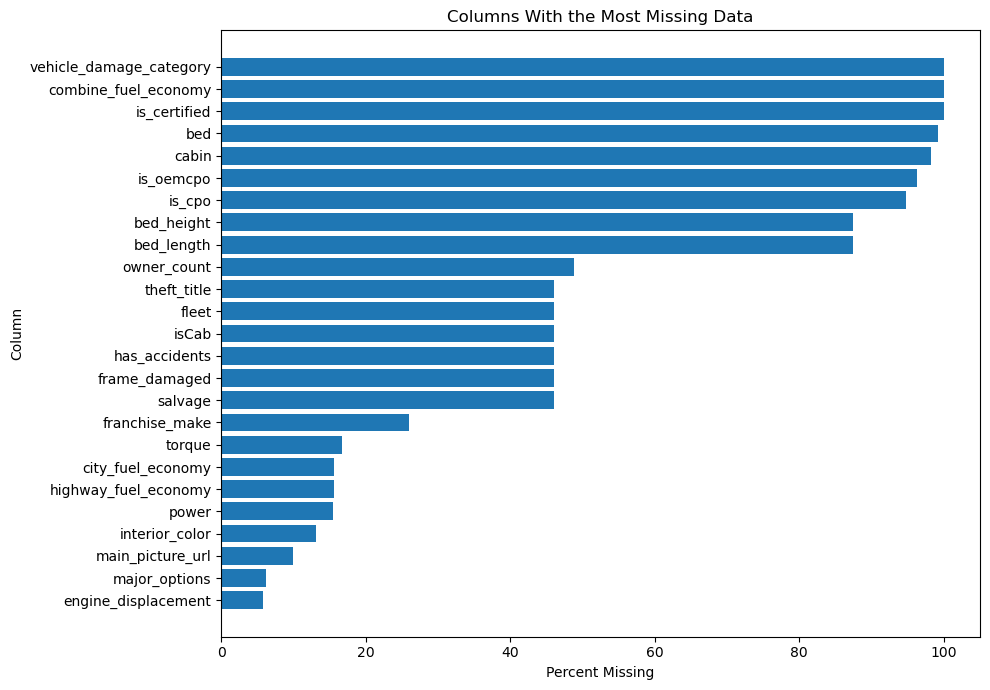


Completely empty columns:
['vehicle_damage_category', 'combine_fuel_economy', 'is_certified']


In [3]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

display(missing)

top_missing = missing[missing["missing_count"] > 0].head(25).sort_values("missing_pct")

if len(top_missing):
    plt.figure(figsize=(10, 7))
    plt.barh(top_missing.index, top_missing["missing_pct"])
    plt.xlabel("Percent Missing")
    plt.ylabel("Column")
    plt.title("Columns With the Most Missing Data")
    plt.tight_layout()
    plt.show()

print("\nCompletely empty columns:")
print(missing[missing["missing_pct"] == 100].index.tolist())

### Practical interpretation
The supplied dataset has **49 columns with at least some missing data** and **3 completely empty columns**:

- `vehicle_damage_category` — 100% missing
- `combine_fuel_economy` — 100% missing
- `is_certified` — 100% missing

Several other variables are extremely sparse: `bed` is about **99.23% missing**, `cabin` about **98.16%**, `is_oemcpo` about **96.30%**, and `is_cpo` about **94.78%**.

The completely empty variables contain no information and should be dropped during preprocessing unless another source can restore them. Very sparse variables require a business-informed decision because missing may mean “not applicable,” “unknown,” or “not reported.”

## 1.3 What columns are likely useless or inappropriate for predicting price?

In [4]:
identifier_like = {
    "Unnamed: 0": "Exported row/index field; should not predict vehicle price.",
    "listing_id": "Listing identifier; essentially unique and likely to encourage memorization.",
    "sp_id": "Seller/dealer identifier. Numeric storage does not make it a continuous quantity.",
    "main_picture_url": "Raw URL/locator with extremely high cardinality.",
}

rows = []

for c in df.columns:
    s = df[c]
    missing_pct = s.isna().mean() * 100
    nunique = s.nunique(dropna=True)
    non_null = s.notna().sum()
    unique_ratio = nunique / max(non_null, 1)

    reasons = []

    if c in identifier_like:
        reasons.append(identifier_like[c])

    if missing_pct == 100:
        reasons.append("100% missing; contains no usable information.")

    if nunique <= 1:
        reasons.append("Constant/no variation.")

    if (
        s.dtype == "object"
        and unique_ratio > 0.95
        and nunique > 100
        and c not in ["description"]
    ):
        reasons.append("Near-unique raw string; likely unsuitable for direct one-hot encoding.")

    if reasons:
        rows.append([
            c,
            round(missing_pct, 2),
            nunique,
            " ".join(reasons)
        ])

useless = pd.DataFrame(
    rows,
    columns=["column", "missing_pct", "unique_non_null", "reason"]
)

display(useless)

,column,missing_pct,unique_non_null,reason
0,Unnamed: 0,0.000,302590,Exported row/index field; should not predict v...
1,bed_height,87.480,1,Constant/no variation.
2,combine_fuel_economy,100.000,0,100% missing; contains no usable information. ...
3,is_certified,100.000,0,100% missing; contains no usable information. ...
4,is_cpo,94.780,1,Constant/no variation.
5,is_oemcpo,96.300,1,Constant/no variation.
6,listing_id,0.000,302587,Listing identifier; essentially unique and lik...
7,main_picture_url,9.890,254865,Raw URL/locator with extremely high cardinality.
8,sp_id,0.000,3275,Seller/dealer identifier. Numeric storage does...
9,vehicle_damage_category,100.000,0,100% missing; contains no usable information. ...


### Practical interpretation
The most obvious raw fields to exclude or reconsider are:

- `Unnamed: 0` — exported index,
- `listing_id` — listing identifier,
- `sp_id` — seller/dealer identifier,
- `main_picture_url` — raw URL,
- completely empty variables, and
- constant variables with no variation.

`sp_id` is especially important: although pandas stores it numerically, dealer ID 400,000 is not meaningfully “larger” than dealer ID 50,000. It should **not** be interpreted as a continuous numeric predictor or included in ordinary numeric correlation analysis.

## 1.4 Clear data errors, malformed strings, spelling/case issues, and datatype problems

In [5]:
object_cols = df.select_dtypes(include="object").columns.tolist()
issues = []

# A. Leading/trailing whitespace
for c in object_cols:
    s = df[c].dropna().astype(str)
    if len(s) == 0:
        continue

    count = int((s != s.str.strip()).sum())
    if count > 0:
        issues.append([
            c,
            "Leading/trailing whitespace",
            count,
            "Strip whitespace before encoding or grouping categories."
        ])

# B. Case variants
for c in object_cols:
    s = df[c].dropna().astype(str).str.strip()
    if s.empty or s.nunique() > 5000:
        continue

    temp = pd.DataFrame({"original": s})
    temp["normalized"] = temp["original"].str.casefold()
    n_variant_groups = int(
        (temp.groupby("normalized")["original"].nunique() > 1).sum()
    )

    if n_variant_groups > 0:
        issues.append([
            c,
            "Capitalization/case variants",
            n_variant_groups,
            "Normalize case carefully after confirming categories are equivalent."
        ])

# C. Dates stored as text
for c in df.columns:
    if "date" in c.lower() and df[c].dtype == "object":
        parsed = pd.to_datetime(df[c], errors="coerce")
        parse_rate = parsed.notna().mean()

        if parse_rate > 0.50:
            issues.append([
                c,
                "Date stored as text/object",
                f"{parse_rate:.1%} parseable",
                "Convert to datetime during preprocessing."
            ])

# D. True measurement columns stored with units.
# IMPORTANT: description is deliberately excluded because it is free text,
# not a measurement column.
measurement_candidates = [
    "back_legroom", "bed_length", "front_legroom",
    "fuel_tank_volume", "height", "length",
    "power", "torque", "wheelbase", "width"
]

for c in measurement_candidates:
    if c in df.columns and df[c].dtype == "object":
        s = df[c].dropna().astype(str)

        if len(s):
            pct = s.str.contains(
                r"\d\s*(in|inch|ft|gal|lb|lbs|hp|rpm|mpg)\b",
                case=False,
                regex=True
            ).mean()

            issues.append([
                c,
                "Numeric measurement stored as string/with units",
                f"{pct:.1%} recognized by unit pattern",
                "Extract numeric value and standardize units."
            ])

# E. Free-text field
if "description" in df.columns:
    issues.append([
        "description",
        "Unstructured high-cardinality free text",
        f"{df['description'].nunique(dropna=True):,} unique non-null values",
        "Do not convert the whole field to a number. Exclude from a basic model or engineer NLP/text features separately."
    ])

# F. Structured list-like field
if "major_options" in df.columns:
    issues.append([
        "major_options",
        "List-like structured information stored as text",
        f"{df['major_options'].nunique(dropna=True):,} unique values",
        "Parse into meaningful option indicators/count features rather than direct one-hot encoding of raw strings."
    ])

quality_issues = pd.DataFrame(
    issues,
    columns=["column", "issue", "evidence", "preprocessing_flag"]
).drop_duplicates()

display(quality_issues)

,column,issue,evidence,preprocessing_flag
0,description,Leading/trailing whitespace,503,Strip whitespace before encoding or grouping c...
1,exterior_color,Leading/trailing whitespace,3,Strip whitespace before encoding or grouping c...
2,model_name,Leading/trailing whitespace,190,Strip whitespace before encoding or grouping c...
3,sp_name,Leading/trailing whitespace,605,Strip whitespace before encoding or grouping c...
4,model_name,Capitalization/case variants,1,Normalize case carefully after confirming cate...
5,sp_name,Capitalization/case variants,1,Normalize case carefully after confirming cate...
6,listed_date,Date stored as text/object,100.0% parseable,Convert to datetime during preprocessing.
7,back_legroom,Numeric measurement stored as string/with units,96.9% recognized by unit pattern,Extract numeric value and standardize units.
8,bed_length,Numeric measurement stored as string/with units,97.6% recognized by unit pattern,Extract numeric value and standardize units.
9,front_legroom,Numeric measurement stored as string/with units,99.2% recognized by unit pattern,Extract numeric value and standardize units.


### Practical interpretation
Several different data-quality problems are present and should not be treated as the same issue.

**Whitespace/case:** `description`, `exterior_color`, `model_name`, and `sp_name` contained whitespace inconsistencies in the completed dataset analysis, while `model_name` and `sp_name` showed case variants. These can split what should be the same category into separate levels.

**Date:** `listed_date` was fully parseable as a date but stored as text, so it should become a true datetime field.

**Measurements:** fields such as `power`, `torque`, dimensions, fuel-tank volume, and legroom contain numeric information stored as strings with units. They should eventually become numeric.

**Free text:** `description` is **not** a measurement column. Its references to values such as horsepower or wheel size are part of natural-language descriptions. The full field should either be excluded from a basic model or handled with a separate NLP/text-feature pipeline.

**Misspellings:** automatic case/whitespace checks cannot prove whether every rare category is a genuine spelling variation. Low-frequency categorical values should therefore be reviewed during preprocessing before any automatic spelling correction is attempted.

## 1.5 Duplicate, target, range, and suspicious-value checks

In [6]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", f"{duplicate_count:,}")

if "price" in df.columns:
    missing_price_count = df["price"].isna().sum()
    nonpositive_price_count = (df["price"].dropna() <= 0).sum()

    print("Missing price:", f"{missing_price_count:,}")
    print("Non-positive price:", f"{nonpositive_price_count:,}")

numeric = df.select_dtypes(include=np.number).columns

ranges = pd.DataFrame({
    "min": df[numeric].min(),
    "p01": df[numeric].quantile(0.01),
    "median": df[numeric].median(),
    "p99": df[numeric].quantile(0.99),
    "max": df[numeric].max()
})

display(ranges)

if "mileage" in df.columns:
    print("\nLargest mileage values:")
    display(
        df.nlargest(10, "mileage")[
            [c for c in ["make_name", "model_name", "year", "mileage", "price"]
             if c in df.columns]
        ]
    )

if "price" in df.columns:
    print("\nLargest price values:")
    display(
        df.nlargest(10, "price")[
            [c for c in ["make_name", "model_name", "year", "mileage", "price"]
             if c in df.columns]
        ]
    )

Exact duplicate rows: 0
Missing price: 0
Non-positive price: 0


,min,p01,median,p99,max
Unnamed: 0,0.000,"4,063.890","202,171.000","400,268.110","404,358.000"
city_fuel_economy,8.000,13.000,22.000,53.000,127.000
combine_fuel_economy,NaN,NaN,NaN,NaN,NaN
daysonmarket,0.000,0.000,34.000,478.000,"2,416.000"
dealer_zip,"1,104.000","22,150.000","73,141.000","95,136.000","97,477.000"
engine_displacement,700.000,"1,300.000","2,500.000","6,700.000","8,400.000"
highway_fuel_economy,11.000,18.000,29.000,50.000,127.000
horsepower,67.000,109.000,241.000,475.000,"1,001.000"
is_certified,NaN,NaN,NaN,NaN,NaN
latitude,25.596,25.692,33.508,43.044,45.637



Largest mileage values:


,make_name,model_name,year,mileage,price
55041,RAM,3500 Chassis,2019,"99,999,988.000","52,610.000"
94537,Chevrolet,Silverado 3500HD Chassis,2020,"590,072.000","45,288.000"
68962,Chevrolet,Silverado 1500,2013,"397,322.000","12,995.000"
209754,Ford,F-250 Super Duty,2000,"392,314.000","7,995.000"
268274,Ford,F-250 Super Duty,2016,"391,398.000","19,963.000"
80077,Volkswagen,Passat,2017,"379,647.000","7,900.000"
42591,Chevrolet,Silverado 2500HD,2003,"378,794.000","10,000.000"
216946,Chevrolet,Express Cargo,2014,"375,000.000","4,995.000"
250145,Ford,F-150,2001,"366,315.000","3,995.000"
152743,Dodge,Sprinter Cargo,2006,"362,460.000","5,995.000"



Largest price values:


,make_name,model_name,year,mileage,price
226252,McLaren,P1,2014,256.000,"1,750,000.000"
147514,Ford,GT,2017,545.000,"1,400,000.000"
31992,Bugatti,Veyron,2008,"8,597.000","1,244,996.000"
132858,Mercedes-Benz,G-Class,2018,NaN,"1,100,000.000"
240086,Ferrari,F12 Berlinetta,2017,149.000,"1,095,000.000"
206696,Ford,Fusion,2014,"80,306.000","999,995.000"
291500,Ferrari,F12 Berlinetta,2017,247.000,"945,900.000"
227515,Porsche,924,1981,71.000,"925,000.000"
214281,Porsche,Carrera GT,2005,"1,901.000","829,991.000"
35897,Lamborghini,Aventador,2020,59.000,"599,900.000"


### Practical interpretation
The completed analysis found **0 exact duplicate rows**, **0 missing prices**, and **0 non-positive prices**.

A major data-quality concern is the maximum recorded mileage of **99,999,988 miles**. This is far beyond a plausible passenger-vehicle lifetime and may represent a sentinel value, placeholder, or data-entry error. It should be explicitly investigated during preprocessing rather than treated as a legitimate extreme observation.

The maximum price was **$1,750,000**. That is unusual but could represent a legitimate exotic or collector vehicle, so price extremes should be validated against make/model/year instead of automatically deleted.

## 1.6 Consolidated preprocessing issue log

In [7]:
flags = []

# Useless/inappropriate predictors
for _, r in useless.iterrows():
    flags.append([
        r["column"],
        r["reason"],
        "Review/drop or transform before modeling."
    ])

# Data quality issues
for _, r in quality_issues.iterrows():
    flags.append([
        r["column"],
        r["issue"],
        r["preprocessing_flag"]
    ])

# Explicit extreme mileage flag
if "mileage" in df.columns and df["mileage"].max(skipna=True) > 1_000_000:
    flags.append([
        "mileage",
        f"Implausibly extreme mileage observed: {df['mileage'].max():,.0f}",
        "Investigate as possible sentinel/data-entry error; replace/remove only after validation."
    ])

# Missing target
if "price" in df.columns and df["price"].isna().any():
    flags.append([
        "price",
        "Missing target values",
        "Exclude missing-target rows from supervised price modeling."
    ])

# Duplicates
if df.duplicated().any():
    flags.append([
        "ALL",
        "Exact duplicate rows",
        "Investigate and remove only true duplicate records."
    ])

preprocessing_flags = pd.DataFrame(
    flags,
    columns=["column", "issue", "recommended_action"]
).drop_duplicates()

display(preprocessing_flags)

,column,issue,recommended_action
0,Unnamed: 0,Exported row/index field; should not predict v...,Review/drop or transform before modeling.
1,bed_height,Constant/no variation.,Review/drop or transform before modeling.
2,combine_fuel_economy,100% missing; contains no usable information. ...,Review/drop or transform before modeling.
3,is_certified,100% missing; contains no usable information. ...,Review/drop or transform before modeling.
4,is_cpo,Constant/no variation.,Review/drop or transform before modeling.
5,is_oemcpo,Constant/no variation.,Review/drop or transform before modeling.
6,listing_id,Listing identifier; essentially unique and lik...,Review/drop or transform before modeling.
7,main_picture_url,Raw URL/locator with extremely high cardinality.,Review/drop or transform before modeling.
8,sp_id,Seller/dealer identifier. Numeric storage does...,Review/drop or transform before modeling.
9,vehicle_damage_category,100% missing; contains no usable information. ...,Review/drop or transform before modeling.


### Practical interpretation
This table is the formal EDA-to-preprocessing handoff. Every important issue discovered in the analysis is documented with a recommended next action.

The highest-priority items are the completely empty columns, identifiers, improperly typed measurements/dates, the unstructured `description` field, very sparse fields, categorical inconsistencies, and the implausible mileage extreme.

# 2. Univariate Distributions

In [8]:
if "price" not in df.columns:
    raise KeyError("The dataset does not contain a column named 'price'.")

eda_df = df[df["price"].notna()].copy()

print(f"Raw rows: {len(df):,}")
print(f"Rows with known price: {len(eda_df):,}")
print(f"Rows excluded because price is missing: {len(df) - len(eda_df):,}")

Raw rows: 302,590
Rows with known price: 302,590
Rows excluded because price is missing: 0


### Practical interpretation
In the completed `CarSales_Large` analysis, **all 302,590 rows had a known price**, so no observations were excluded from target-oriented EDA.

## 2.1 Numeric descriptive statistics

In [9]:
numeric_cols = eda_df.select_dtypes(include=np.number).columns.tolist()

stats = eda_df[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(stats)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Unnamed: 0,"302,590.000","202,223.060","116,732.043",0.000,"4,063.890","20,358.450","101,103.250","202,171.000","303,376.500","384,165.550","400,268.110","404,358.000"
city_fuel_economy,"255,261.000",22.893,8.889,8.000,13.000,15.000,18.000,22.000,26.000,31.000,53.000,127.000
combine_fuel_economy,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daysonmarket,"302,590.000",72.190,105.813,0.000,0.000,2.000,14.000,34.000,77.000,279.000,478.000,"2,416.000"
dealer_zip,"302,590.000","60,565.357","22,897.903","1,104.000","22,150.000","27,616.000","33,619.000","73,141.000","78,729.000","89,117.000","95,136.000","97,477.000"
engine_displacement,"285,071.000","2,932.351","1,322.871",700.000,"1,300.000","1,400.000","2,000.000","2,500.000","3,600.000","5,700.000","6,700.000","8,400.000"
highway_fuel_economy,"255,261.000",29.802,7.906,11.000,18.000,20.000,25.000,29.000,34.000,40.000,50.000,127.000
horsepower,"285,071.000",245.670,90.979,67.000,109.000,132.000,172.000,241.000,300.000,400.000,475.000,"1,001.000"
is_certified,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,"302,590.000",33.761,4.476,25.596,25.692,27.948,29.767,33.508,37.328,40.685,43.044,45.637


### Practical interpretation
The numeric summary shows strong skew and extreme tails in several variables.

For `price`, the median is about **$25,097**, while the 99th percentile is about **$87,395** and the maximum reaches **$1.75 million**. That gap confirms a strongly right-skewed price distribution.

For `mileage`, the median is about **12,410 miles** and the 99th percentile about **189,354 miles**, but the maximum is **99,999,988 miles**, which is not merely a normal statistical outlier and should be investigated as a likely data-quality problem.

`daysonmarket` is also highly right-skewed: the median is **34 days**, while the observed maximum is **2,416 days**.

## 2.2 Histograms of numeric variables

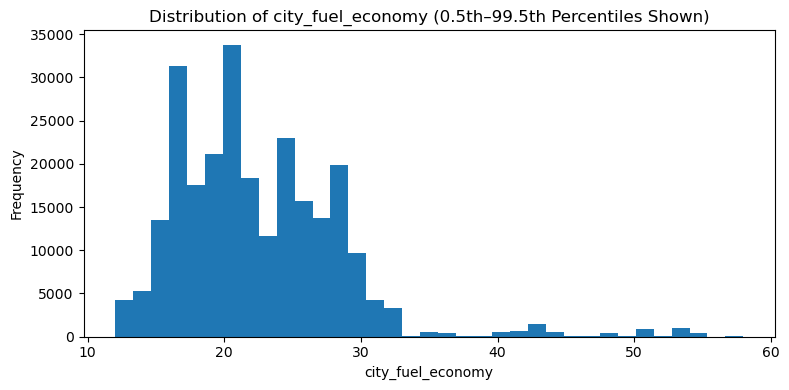

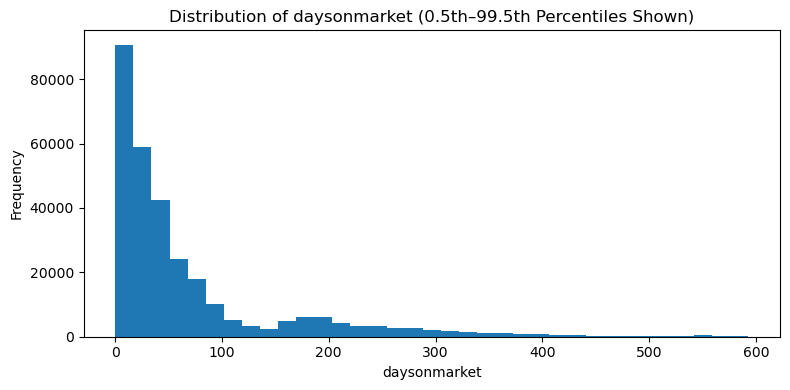

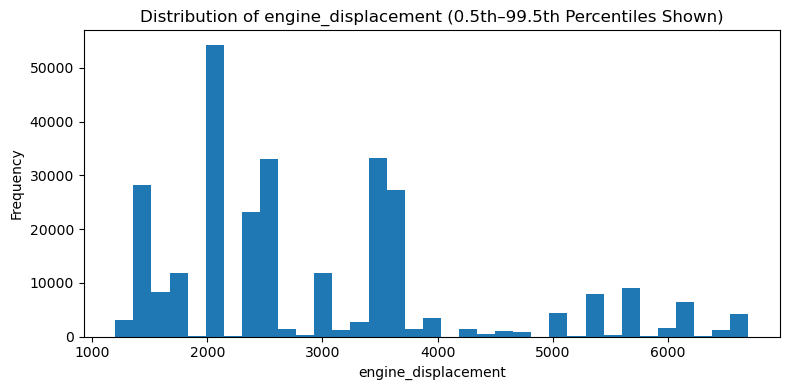

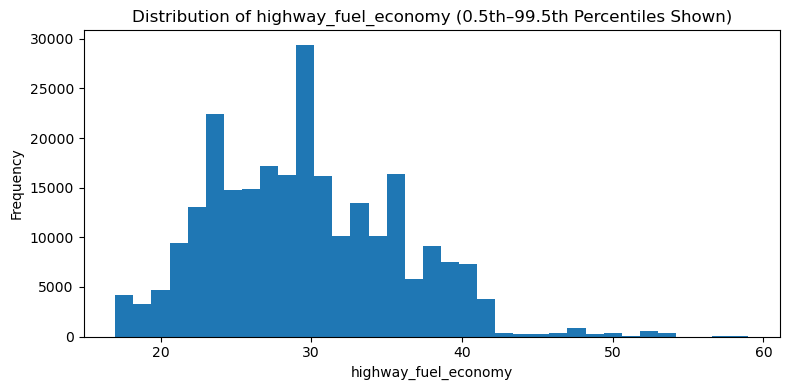

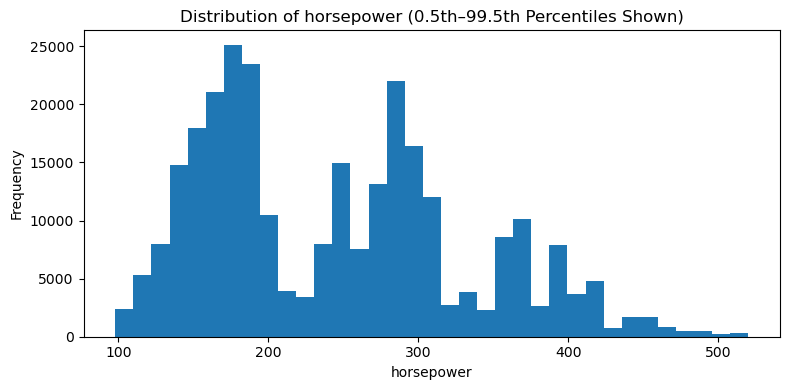

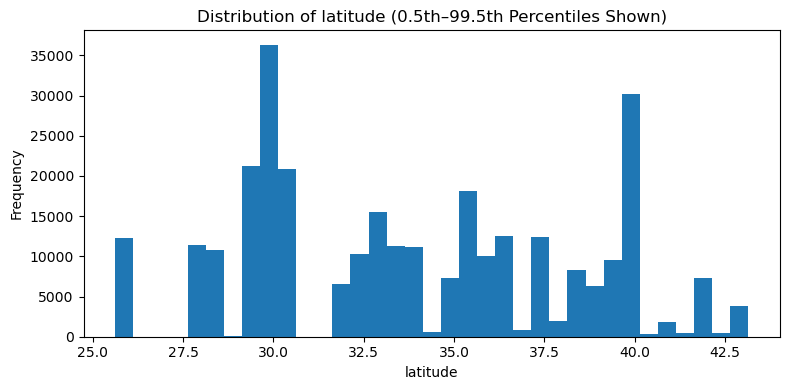

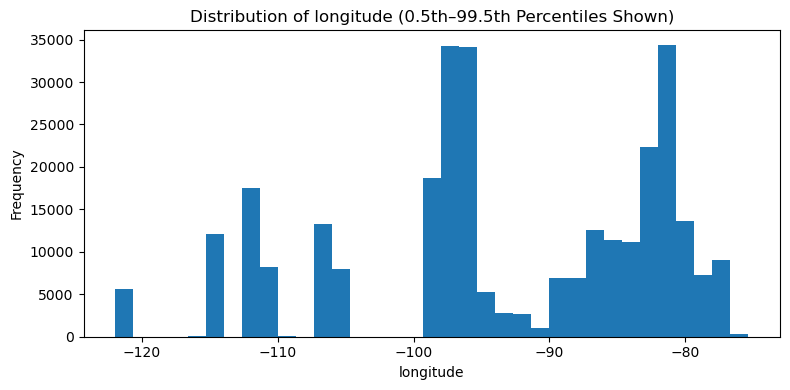

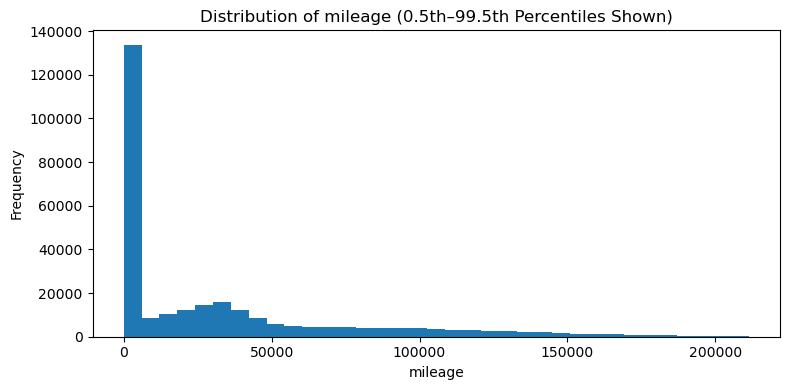

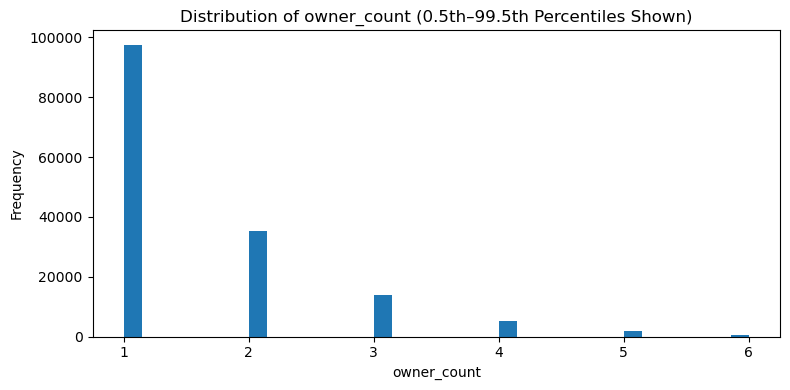

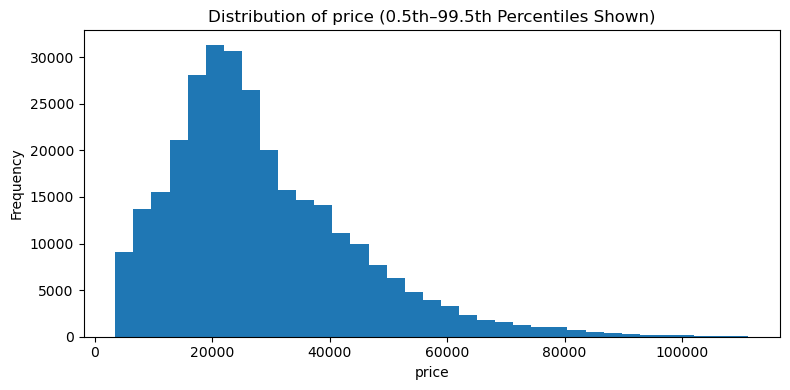

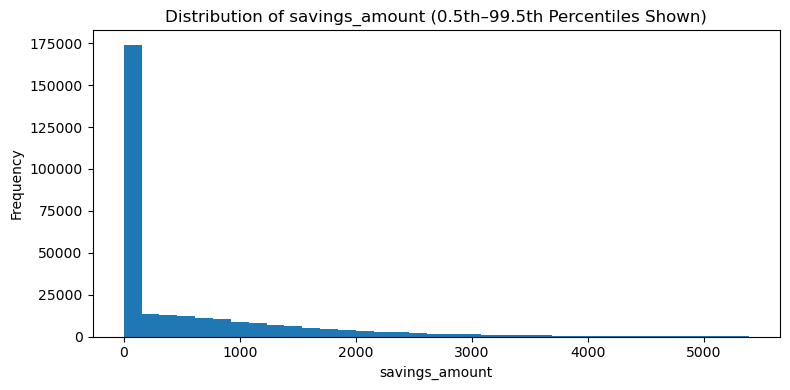

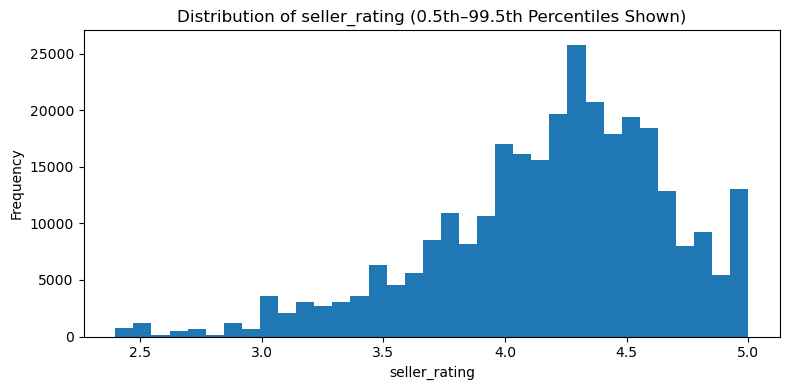

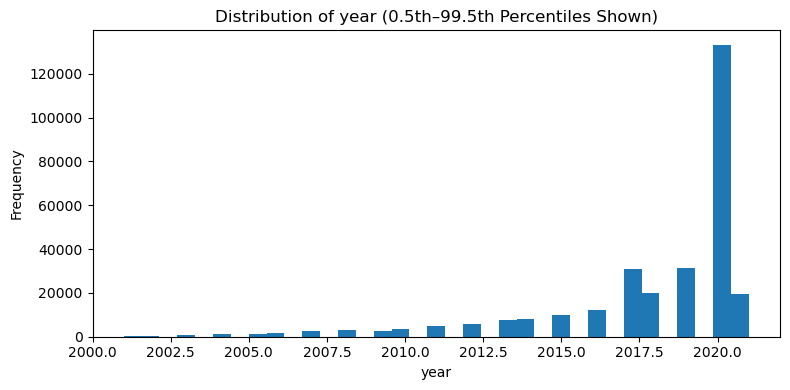

In [10]:
identifier_numeric = {
    "Unnamed: 0",
    "listing_id",
    "dealer_zip",
    "sp_id"
}

plot_cols = [
    c for c in numeric_cols
    if c not in identifier_numeric
    and eda_df[c].nunique(dropna=True) > 5
    and not eda_df[c].isna().all()
]

for c in plot_cols:
    s = eda_df[c].dropna()

    if s.empty:
        continue

    # Clip only the visual display to keep a few extremes
    # from compressing the main histogram.
    lo, hi = s.quantile([0.005, 0.995])
    shown = s[(s >= lo) & (s <= hi)]

    plt.figure(figsize=(8, 4))
    plt.hist(shown, bins=35)
    plt.xlabel(c)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {c} (0.5th–99.5th Percentiles Shown)")
    plt.tight_layout()
    plt.show()

### Practical interpretation
The histograms show that many numeric vehicle variables are not normally distributed. Price, mileage, days on market, savings, and several specification variables have asymmetric distributions or long tails.

This matters practically because:

- mean-based summaries can be strongly influenced by extreme listings,
- transformations such as `log(price)` may be useful in later modeling,
- robust scaling may be preferable for some algorithms, and
- suspicious extremes should be validated before any outlier-removal rule is applied.

The plots clip only the **display range**; no records are removed from the actual dataset.

## 2.3 Which numeric columns have significant outliers?

In [11]:
outliers = []

for c in plot_cols:
    s = eda_df[c].dropna()

    if s.empty:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        lower = q1
        upper = q3
        count = 0
        pct = 0.0
    else:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (s < lower) | (s > upper)
        count = int(mask.sum())
        pct = count / len(s) * 100

    outliers.append([
        c, q1, q3, lower, upper, count, pct
    ])

outlier_table = pd.DataFrame(
    outliers,
    columns=[
        "column", "Q1", "Q3",
        "lower_fence", "upper_fence",
        "outlier_count", "outlier_pct"
    ]
).sort_values("outlier_pct", ascending=False)

display(outlier_table)

significant_outliers = outlier_table[
    outlier_table["outlier_pct"] >= 1
]

print("\nColumns with at least 1% IQR-flagged observations:")
display(significant_outliers)

,column,Q1,Q3,lower_fence,upper_fence,outlier_count,outlier_pct
1,daysonmarket,14.000,77.000,-80.500,171.500,41769,13.804
12,year,"2,017.000","2,020.000","2,012.500","2,024.500",29901,9.882
7,mileage,7.000,"46,393.250","-69,572.375","115,972.625",22353,7.826
10,savings_amount,0.000,813.000,"-1,219.500","2,032.500",23606,7.801
8,owner_count,1.000,2.000,-0.500,3.500,8226,5.317
2,engine_displacement,"2,000.000","3,600.000",-400.000,"6,000.000",12160,4.266
9,price,"17,420.000","37,070.000","-12,055.000","66,545.000",10023,3.312
11,seller_rating,3.930,4.515,3.053,5.393,9552,3.196
0,city_fuel_economy,18.000,26.000,6.000,38.000,7604,2.979
3,highway_fuel_economy,25.000,34.000,11.500,47.500,3274,1.283



Columns with at least 1% IQR-flagged observations:


,column,Q1,Q3,lower_fence,upper_fence,outlier_count,outlier_pct
1,daysonmarket,14.000,77.000,-80.500,171.500,41769,13.804
12,year,"2,017.000","2,020.000","2,012.500","2,024.500",29901,9.882
7,mileage,7.000,"46,393.250","-69,572.375","115,972.625",22353,7.826
10,savings_amount,0.000,813.000,"-1,219.500","2,032.500",23606,7.801
8,owner_count,1.000,2.000,-0.500,3.500,8226,5.317
2,engine_displacement,"2,000.000","3,600.000",-400.000,"6,000.000",12160,4.266
9,price,"17,420.000","37,070.000","-12,055.000","66,545.000",10023,3.312
11,seller_rating,3.930,4.515,3.053,5.393,9552,3.196
0,city_fuel_economy,18.000,26.000,6.000,38.000,7604,2.979
3,highway_fuel_economy,25.000,34.000,11.500,47.500,3274,1.283


### Practical interpretation
Using the 1.5×IQR rule, the completed dataset showed the largest outlier shares in:

- `daysonmarket` — **13.80%**
- `year` — **9.88%**
- `mileage` — **7.83%**
- `savings_amount` — **7.80%**
- `owner_count` — **5.32%**
- `engine_displacement` — **4.27%**
- `price` — **3.31%**
- `seller_rating` — **3.20%**
- `city_fuel_economy` — **2.98%**
- `highway_fuel_economy` — **1.28%**

These are statistically unusual values, but not all are errors. Older cars, long-running listings, high-mileage cars, and expensive vehicles can be legitimate. The **99,999,988-mile** maximum is different because it is implausible enough to warrant a specific data-quality investigation.

## 2.4 Categorical columns and high-cardinality features

In [12]:
cat_cols = eda_df.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

cardinality = pd.DataFrame({
    "unique_non_null": eda_df[cat_cols].nunique(dropna=True),
    "missing_count": eda_df[cat_cols].isna().sum(),
    "missing_pct": (eda_df[cat_cols].isna().mean() * 100).round(2)
}).sort_values("unique_non_null", ascending=False)

display(cardinality)

HIGH_CARDINALITY_THRESHOLD = 50

high_cardinality = cardinality[
    cardinality["unique_non_null"] > HIGH_CARDINALITY_THRESHOLD
]

print(
    f"\nHigh-cardinality categorical/object features "
    f"(> {HIGH_CARDINALITY_THRESHOLD} unique values):"
)
display(high_cardinality)

,unique_non_null,missing_count,missing_pct
description,260806,6687,2.210
main_picture_url,254865,29939,9.890
major_options,50632,18599,6.150
trimId,23808,11338,3.750
interior_color,9731,39451,13.040
exterior_color,7604,5353,1.770
trim_name,5713,11380,3.760
sp_name,3239,0,0.000
power,1631,46865,15.490
torque,1601,50601,16.720



High-cardinality categorical/object features (> 50 unique values):


,unique_non_null,missing_count,missing_pct
description,260806,6687,2.210
main_picture_url,254865,29939,9.890
major_options,50632,18599,6.150
trimId,23808,11338,3.750
interior_color,9731,39451,13.040
exterior_color,7604,5353,1.770
trim_name,5713,11380,3.760
sp_name,3239,0,0.000
power,1631,46865,15.490
torque,1601,50601,16.720


### Practical interpretation
The completed dataset contained **21 object/categorical fields with more than 50 unique values**. The largest included:

- `description` — **260,806** unique values
- `main_picture_url` — **254,865**
- `major_options` — **50,632**
- `trimId` — **23,808**
- `interior_color` — **9,731**
- `exterior_color` — **7,604**
- `trim_name` — **5,713**
- `sp_name` — **3,239**
- `model_name` — **1,054**
- `make_name` — **74**

High cardinality does **not** automatically mean useless. `make_name`, `model_name`, and trim information can strongly affect price.

However, several fields appear high-cardinality only because they currently have the wrong datatype. `power`, `torque`, dimensions, legroom, and fuel-tank volume should become numeric, while `listed_date` should become datetime. Those variables should not be treated as ordinary high-cardinality categories.

## 2.5 Value counts and frequency plots for manageable categorical features


city


,count
city,
Houston,32723
San Antonio,18657
Columbus,13717
Miami,13653
Jacksonville,12653
Las Vegas,12206
Tampa,11431
Phoenix,11111
Dallas,11032


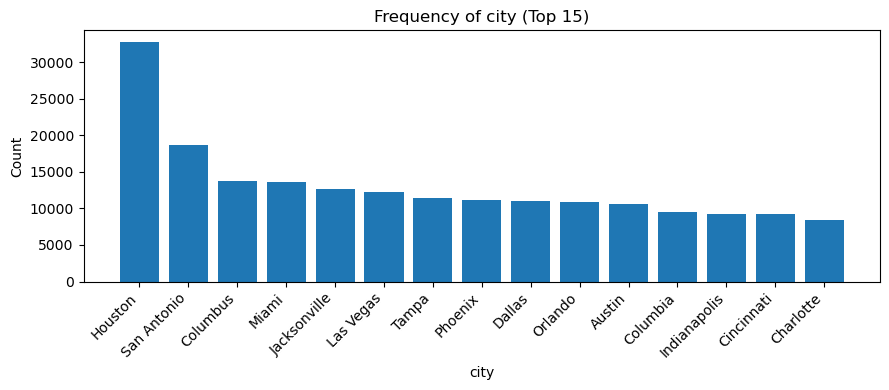


bed


,count
bed,
<MISSING>,300273
Short,1366
Long,625
Regular,326


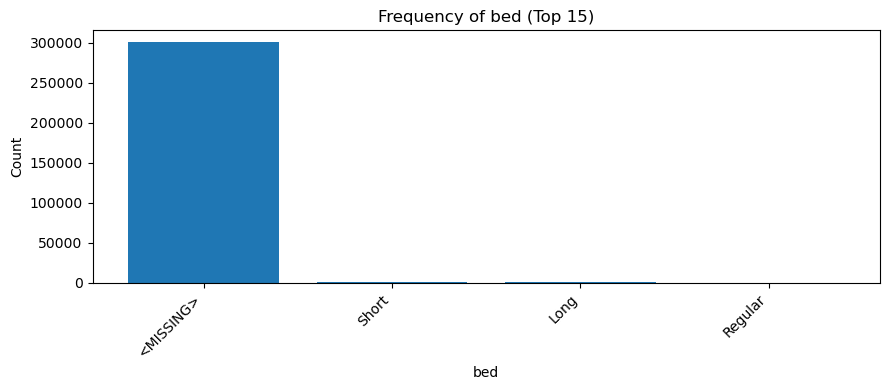


body_type


,count
body_type,
SUV / Crossover,139227
Sedan,82180
Pickup Truck,41569
Hatchback,9645
Coupe,8870
Minivan,7954
Van,4385
Wagon,4192
Convertible,3194


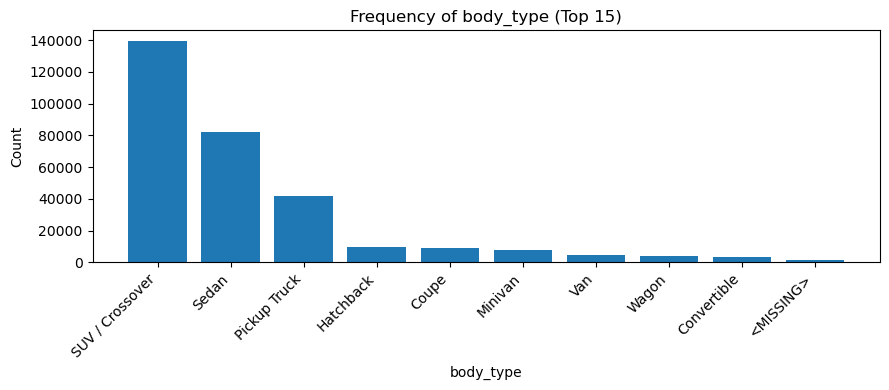


cabin


,count
cabin,
<MISSING>,297035
Crew Cab,4414
Extended Cab,754
Regular Cab,209
Large Crew Cab,178


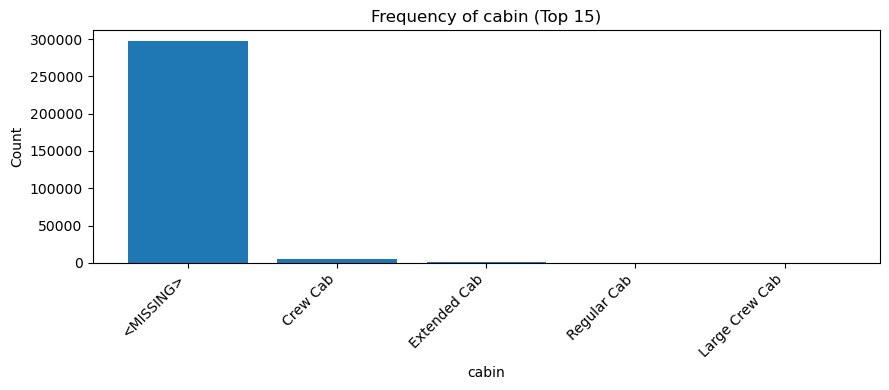


fleet


,count
fleet,
<MISSING>,139504
False,120034
True,43052


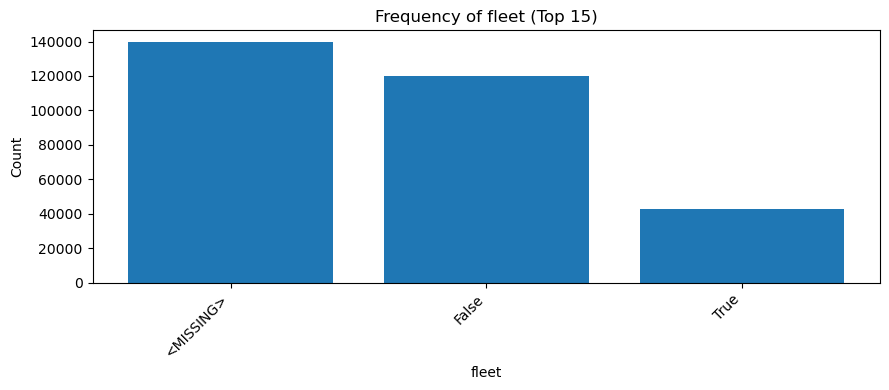


frame_damaged


,count
frame_damaged,
False,160865
<MISSING>,139504
True,2221


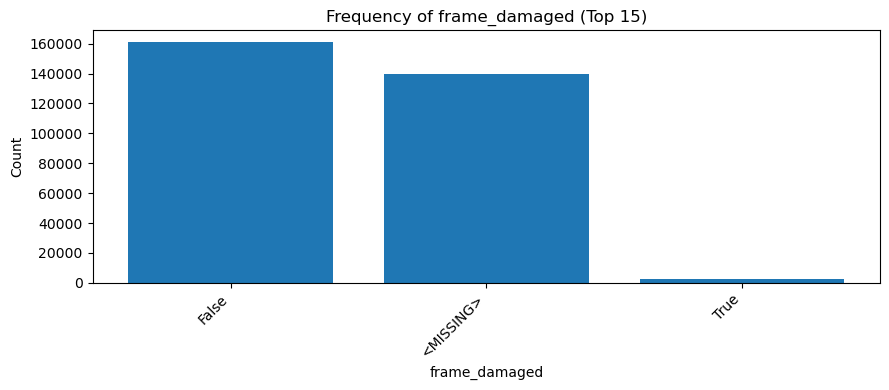


franchise_dealer


,count
franchise_dealer,
True,224856
False,77734


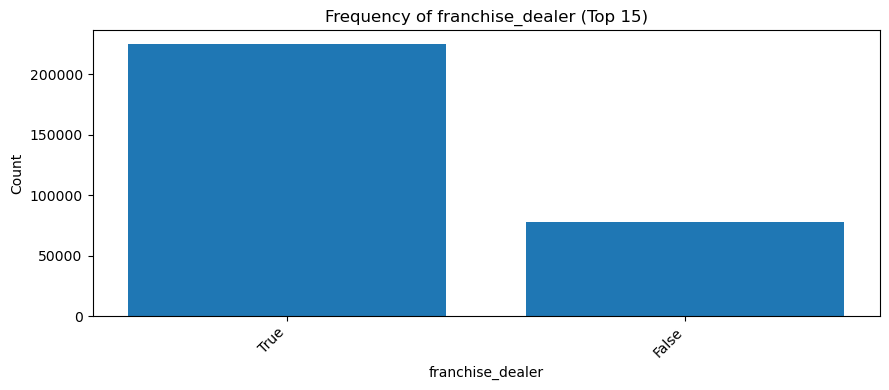


fuel_type


,count
fuel_type,
Gasoline,264402
Flex Fuel Vehicle,14372
<MISSING>,8576
Hybrid,7332
Diesel,4065
Biodiesel,2016
Electric,1812
Compressed Natural Gas,15


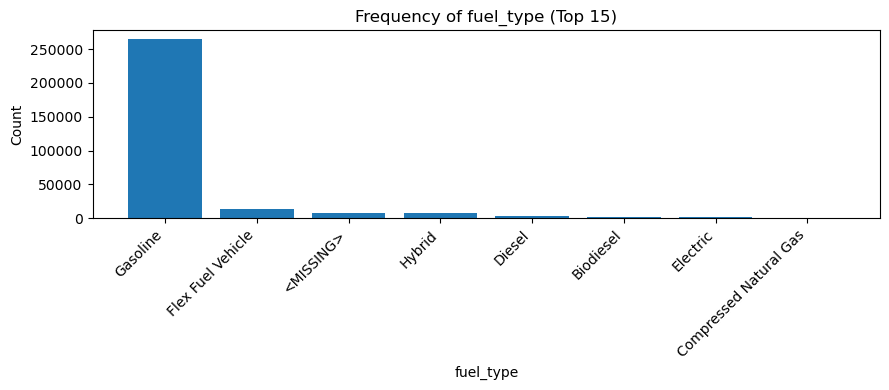


has_accidents


,count
has_accidents,
<MISSING>,139504
False,135636
True,27450


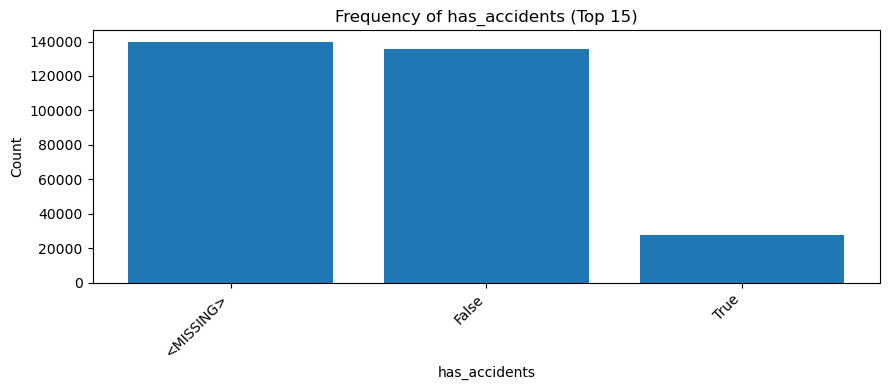


isCab


,count
isCab,
<MISSING>,139504
False,126910
True,36176


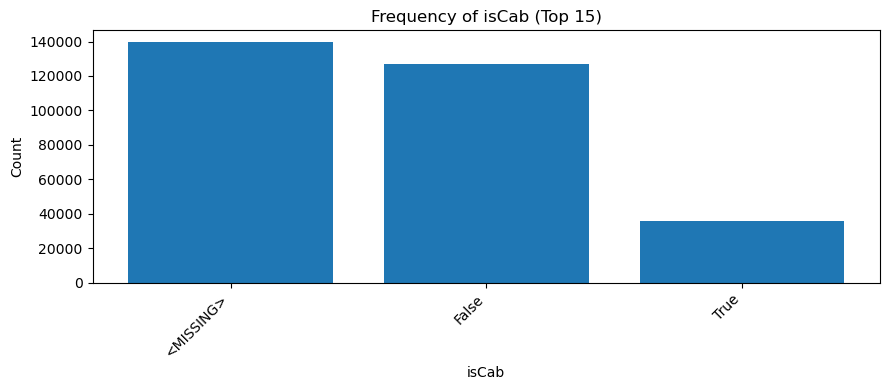


is_new


,count
is_new,
False,159217
True,143373


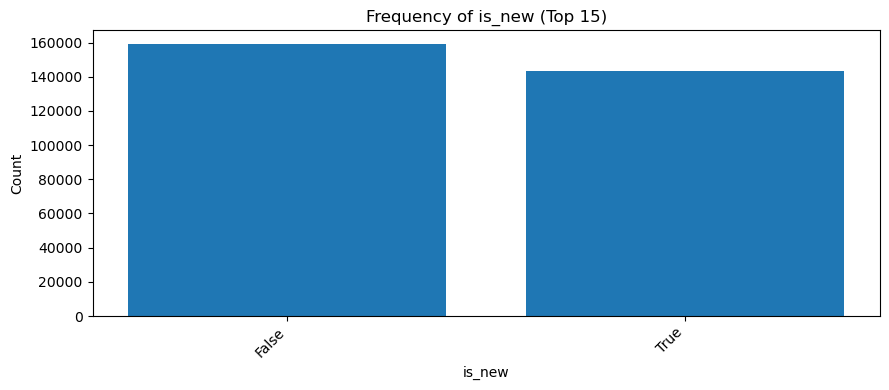


listing_color


,count
listing_color,
WHITE,67272
BLACK,59639
SILVER,39875
GRAY,39813
UNKNOWN,38740
BLUE,24572
RED,24504
BROWN,2359
GREEN,2230


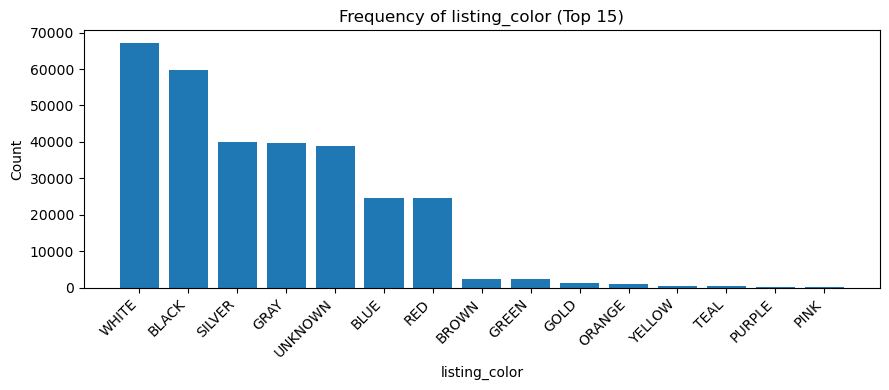


maximum_seating


,count
maximum_seating,
5 seats,191386
7 seats,32403
6 seats,25464
8 seats,20094
<MISSING>,15883
4 seats,9745
2 seats,3916
3 seats,2388
15 seats,696


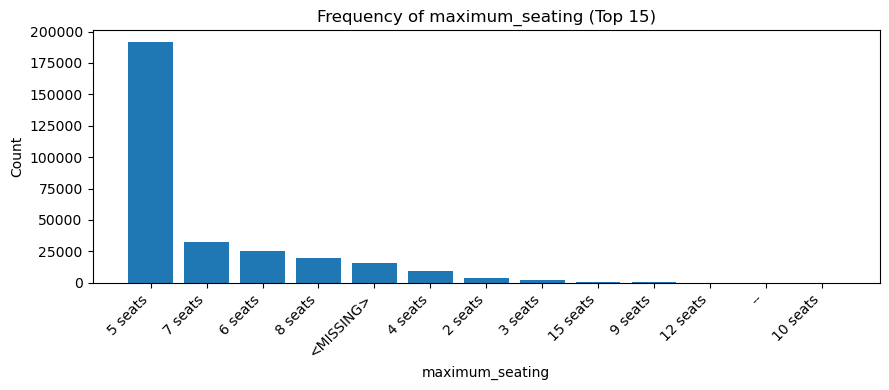


salvage


,count
salvage,
False,161182
<MISSING>,139504
True,1904


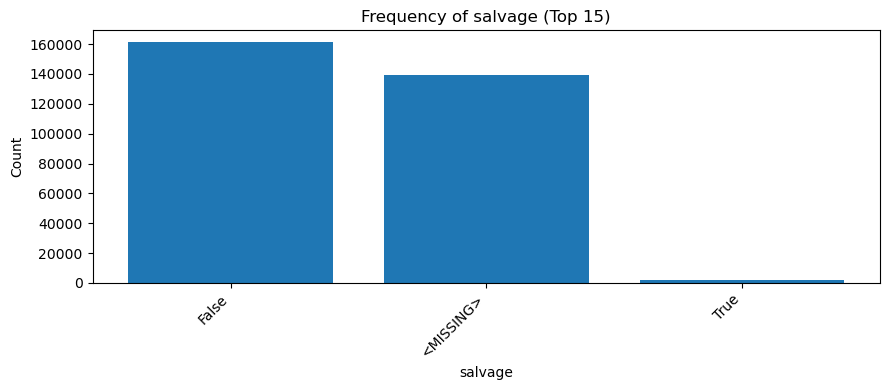


theft_title


,count
theft_title,
False,162300
<MISSING>,139504
True,786


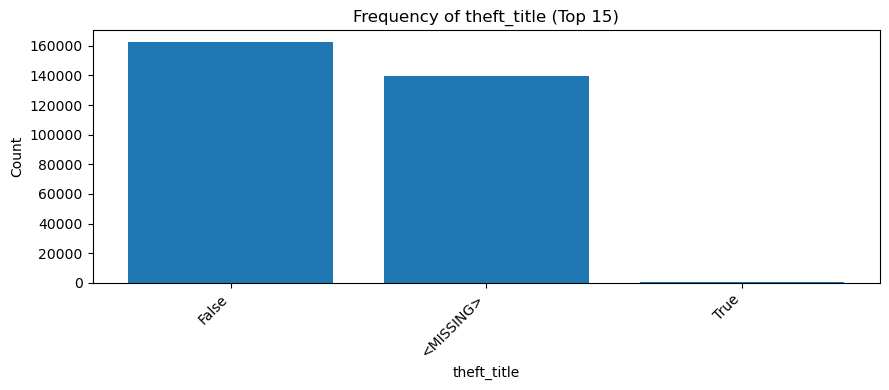


transmission


,count
transmission,
A,241622
CVT,46534
<MISSING>,7585
M,5638
Dual Clutch,1211


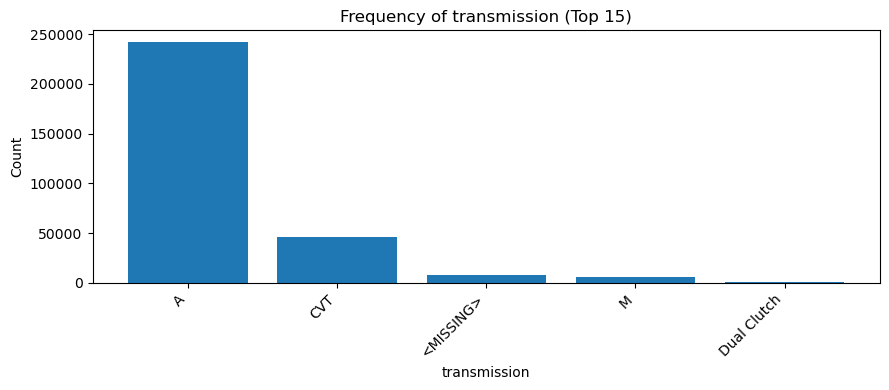


wheel_system


,count
wheel_system,
FWD,149449
AWD,52667
4WD,42579
RWD,26334
4X2,16917
<MISSING>,14644


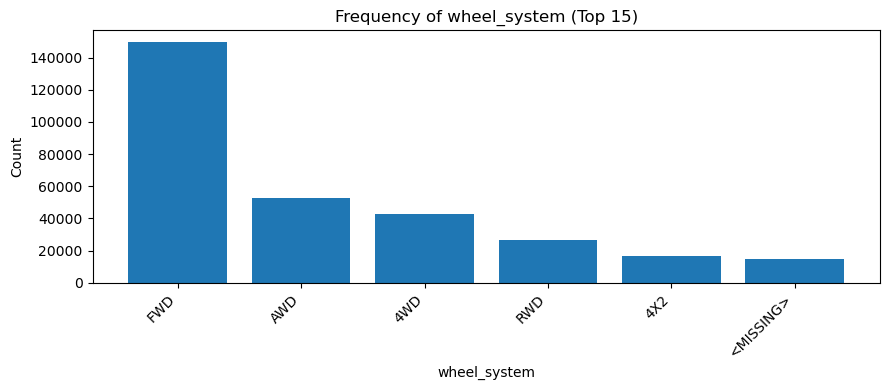


wheel_system_display


,count
wheel_system_display,
Front-Wheel Drive,149449
All-Wheel Drive,52667
Four-Wheel Drive,42579
Rear-Wheel Drive,26334
4X2,16917
<MISSING>,14644


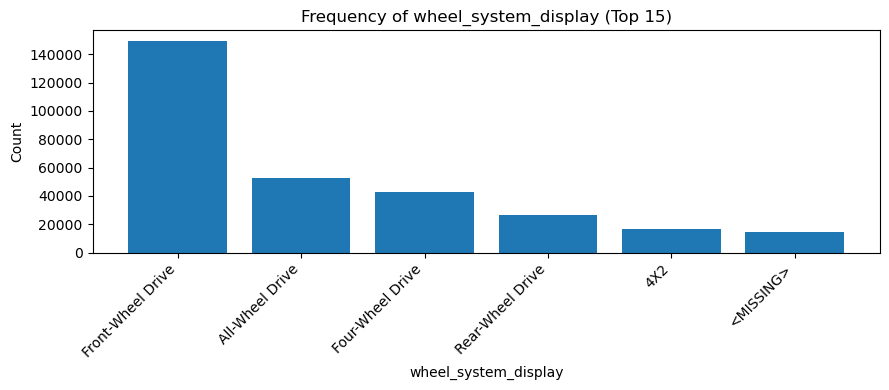

In [13]:
manageable = [
    c for c in cat_cols
    if 2 <= eda_df[c].nunique(dropna=True) <= 30
]

for c in manageable:
    counts = (
        eda_df[c]
        .fillna("<MISSING>")
        .value_counts()
        .head(15)
    )

    print(f"\n{c}")
    display(counts.to_frame("count"))

    plt.figure(figsize=(9, 4))
    plt.bar(counts.index.astype(str), counts.values)
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.title(f"Frequency of {c} (Top 15)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Practical interpretation
The frequency tables and plots show whether categorical levels are balanced or dominated by a few common groups.

This matters because very rare categories can produce unstable model estimates, while dominant categories can strongly influence overall results. In preprocessing, genuinely rare levels may need to be grouped into an `Other` category, but only after confirming that doing so does not erase meaningful vehicle distinctions.

## 2.6 Top values for high-cardinality fields

In [14]:
for c in high_cardinality.index:
    print(
        f"\n{c}: "
        f"{eda_df[c].nunique(dropna=True):,} unique non-null values"
    )

    display(
        eda_df[c]
        .fillna("<MISSING>")
        .value_counts()
        .head(15)
        .to_frame("count")
    )


description: 260,806 unique non-null values


,count
description,
<MISSING>,6687
[!@@Additional Info@@!]Bluetooth,257
"BRING YOUR W2 GET YOUR CAR AND YOUR TAX CHECK TODAY--WE DO TAXES --NO CREDIT CHECK BUY HERE PAY HERE FINANCING --8500 ATLANTIC BLVD (ACROSS FROM MARCH MOTORS). MOTORMALL PROVIDES A LIMITED WARRANTY WITH ALL VEHICLES. WARRANTY DETAILS CAN BE SEE PRIOR TO THE SALE AT THE DEALERSHIP, OR ARE AVAILABLE UPON WRITTEN REQUEST FOR WEB, MAIL AND TELEPHONE SALES. WE SERVICE WHAT WE SELL, BEFORE AND AFTER THE SALE! WE BUY CARS FOR CASH! TRADES WELCOME!----IF YOU DO NOT LIKE THE CAR YOU CHOSE, WE WILL GIVE YOU A FULL CREDIT OF THE PURCHASE PRICE TOWARDS AN EXCHANGE FOR ANOTHER VEHICLE ON OUR LOT WITHIN THE FIRST SEVEN (7) DAYS OF PURCHASE (SUBJECT TO THE CAR BEING IN THE SAME CONDITION AS OF THE DATE OF SALE). ---. COME VISIT OUR CUSTOMER FRIENDLY SALES TEAM AT MOTORMALL WHERE WE HANDLE EVERYTHING IN HOUSE. FROM SALES TO SERVICE AND EVERYTHING IN BETWEEN. WE ARE A BUY HERE PAY HERE, NO CREDIT CHECK NEEDED. HASSLE FREE FINANCING TO STAY WITHIN YOUR BUDGET. TITLE IS BRANDED, VISIT DEALER FOR DETAILS. MILEAGE ON VEHICLES OLDER THAN 10 YEARS REFLECTS ODOMETER MILEAGE AND IS NOT GUARANTEED. *DISCOUNTED CASH PRICE FOR CASH PURCHASE ONLY, PRICE MUST BE PAID IN FULL AT TIME OF PURCHASE, AND DOES NOT INCLUDE GOVERNMENT FEES, TAXES OR DEALER FEES.",169
"[!@@Additional Info@@!]Front Wheel Drive,Power Steering,ABS,4-Wheel Disc Brakes,Brake Assist,Wheel Covers,Steel Wheels,Tires - Front Performance,Tires - Rear Performance,Temporary Spare Tire,Power Mirror(s),Rear Defrost,Intermittent Wipers,Daytime Running Lights,Automatic Headlights,AM/FM Stereo,MP3 Player,Steering Wheel Audio Controls,Bluetooth Connection,Auxiliary Audio Input,Bucket Seats,Rear Bench Seat,Adjustable Steering Wheel,Trip Computer,Power Windows,Keyless Entry,Power Door Locks,Cruise Control,Adaptive Cruise Control,Climate Control,A/C,Cloth Seats,Driver Vanity Mirror,Passenger Vanity Mirror,Floor Mats,Power Windows,Power Door Locks,Trip Computer,Security System,Engine Immobilizer,Traction Control,Stability Control,Traction Control,Front Side Air Bag,Lane Departure Warning,Lane Keeping Assist,Lane Departure Warning,Tire Pressure Monitor,Driver Air Bag,Passenger Air Bag,Front Head Air Bag,Rear Head Air Bag,Passenger Air Bag Sensor,Child Safety Locks,Back-Up Camera",128
"The Price you see is the price you will pay. NOT A PENNY MORE. You may qualify for additional incentives. We offer preferred pricing and VIP service to you directly through the Internet department. If you are looking for The NO Hassle Approach with No Back and Forth, then for more information please visit us at www.bomninchevrolet.com. Accessories and color may vary. Quoted price subject to change without notice to correct errors or omissions or in the event of inventory fluctuations. This is an individualized price quote and is valid solely in connection with a purchase by you, the recipient. Quoted price good on date of publication only. Price already include applicable manufacturer rebates and incentives which are subject to manufacturer incentive or rebate qualification criteria and requirements, and which may be contingent upon manufacturer finance company approval. Manufacturer incentive data (customer rebates) is provided by third parties and believed to be accurate as of the time of publication. Manufacturer incentives may expire at any time. Dealer service/document fee of $895 is not included in quoted price. Tax, tag, electronic and registration fees not included. Standard features are based upon trim level. Price does not include dealer installed options or equipment. All features not on all vehicles. See Accessories listing for accessories particular to this vehicle. Internet Price includes the following incentives:$750 - Chevrolet Select Market Conquest Program. Exp. 09/30/2020 15% Msrp - Chevrolet Consumer Cash Program. Exp. 09/30/2020[!@@Additional Info@@!]Preferred Equipment Group 1LS,3.50 Final Drive Axle Ratio,17"" Aluminum Wheels,Fro


main_picture_url: 254,865 unique non-null values


,count
main_picture_url,
<MISSING>,29939
https://static.cargurus.com/images/forsale/2019/11/09/02/31/2020_mazda_cx-5-pic-2938050670830075085-152x114.jpeg,170
https://static.cargurus.com/images/forsale/2020/01/29/21/28/2020_gmc_sierra_1500-pic-1910519831816536206-152x114.jpeg,132
https://static.cargurus.com/images/forsale/2017/12/15/07/52/2014_ford_focus-pic-8272347518435574514-152x114.jpeg,107
https://static.cargurus.com/images/forsale/2020/01/14/06/10/2020_honda_civic-pic-8659105345295960931-152x114.jpeg,105
https://static.cargurus.com/images/forsale/2019/07/18/21/32/2019_honda_civic_coupe-pic-8210511563256242892-152x114.jpeg,91
https://static.cargurus.com/images/forsale/2019/02/20/22/50/2016_jeep_wrangler_unlimited-pic-2687082065598025965-152x114.jpeg,89
https://static.cargurus.com/images/forsale/2019/11/23/13/53/2020_mazda_cx-5-pic-1755891255741322871-152x114.jpeg,79
https://static.cargurus.com/images/forsale/2020/05/09/03/46/2020_chevrolet_malibu-pic-6857389212590742089-152x114.jpeg,78



major_options: 50,632 unique non-null values


,count
major_options,
<MISSING>,18599
"['Alloy Wheels', 'Bluetooth', 'Backup Camera']",9878
['Steel Wheels'],4968
['Alloy Wheels'],4573
"['Steel Wheels', 'Bluetooth', 'Backup Camera']",3762
['Bluetooth'],3335
"['Bluetooth', 'Backup Camera']",3198
['Backup Camera'],2978
"['Alloy Wheels', 'Bluetooth', 'Backup Camera', 'Android Auto', 'CarPlay']",2883


... (32 outputs left out)


bed_length: 79 unique non-null values


,count
bed_length,
<MISSING>,264711
67.1 in,7413
67.4 in,4594
69.9 in,4392
76.3 in,2617
78.9 in,2604
69.3 in,1718
60.3 in,1336
98.3 in,1149



make_name: 74 unique non-null values


,count
make_name,
Ford,41161
Chevrolet,34277
Toyota,25142
Nissan,24175
Honda,21536
Jeep,15185
Hyundai,14394
Kia,12162
Volkswagen,10118


### Practical interpretation
The top-value tables help distinguish meaningful high-cardinality variables from fields that should be transformed or excluded.

For example:

- `description` is essentially free text,
- `main_picture_url` is a locator rather than a vehicle characteristic,
- `major_options` contains structured option information that should be parsed,
- `model_name` and `make_name` are meaningful vehicle characteristics, and
- measurement fields such as `power` and `length` should be converted to numeric rather than encoded as categories.

# 3. Bivariate Relationships

## 3.1 What numeric features correlate with price?

,pearson_r,spearman_rho,abs_pearson
horsepower,0.605,0.602,0.605
engine_displacement,0.362,0.366,0.362
year,0.358,0.607,0.358
highway_fuel_economy,-0.243,-0.388,0.243
owner_count,-0.213,-0.450,0.213
city_fuel_economy,-0.169,-0.341,0.169
mileage,-0.106,-0.622,0.106
seller_rating,0.089,0.057,0.089
daysonmarket,0.051,0.028,0.051
savings_amount,0.041,-0.363,0.041


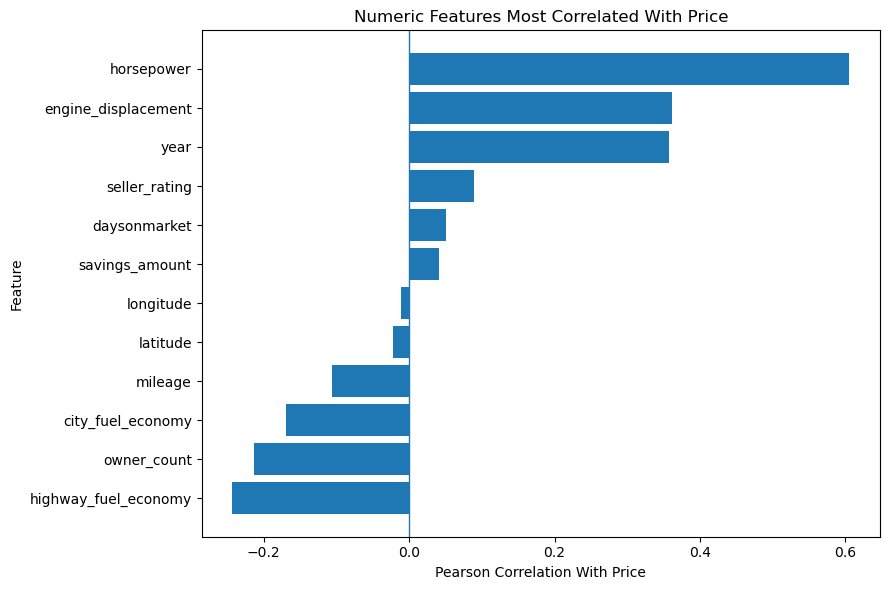

In [15]:
num_corr = eda_df.select_dtypes(include=np.number).copy()

# Exclude identifiers/geographic codes that should not be interpreted
# as continuous numeric measurements.
drop_corr = [
    c for c in [
        "Unnamed: 0",
        "listing_id",
        "dealer_zip",
        "sp_id"
    ]
    if c in num_corr.columns
]

num_corr = num_corr.drop(columns=drop_corr, errors="ignore")

pearson = (
    num_corr.corr(method="pearson")["price"]
    .drop("price")
    .dropna()
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

spearman = (
    num_corr.corr(method="spearman")["price"]
    .drop("price")
    .dropna()
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

price_relationships = pd.concat(
    [
        pearson.rename("pearson_r"),
        spearman.rename("spearman_rho")
    ],
    axis=1
)

price_relationships["abs_pearson"] = (
    price_relationships["pearson_r"].abs()
)

price_relationships = price_relationships.sort_values(
    "abs_pearson",
    ascending=False
)

display(price_relationships)

top = price_relationships.head(15).sort_values("pearson_r")

plt.figure(figsize=(9, 6))
plt.barh(top.index, top["pearson_r"])
plt.axvline(0, linewidth=1)
plt.xlabel("Pearson Correlation With Price")
plt.ylabel("Feature")
plt.title("Numeric Features Most Correlated With Price")
plt.tight_layout()
plt.show()

In [16]:
print("TOP NUMERIC RELATIONSHIPS WITH PRICE")
print("-" * 65)

for feature, row in price_relationships.head(10).iterrows():
    pearson_r = row["pearson_r"]
    spearman_r = row["spearman_rho"]

    p_direction = "positive" if pearson_r > 0 else "negative"
    p_strength = (
        "strong" if abs(pearson_r) >= 0.50
        else "moderate" if abs(pearson_r) >= 0.30
        else "weak"
    )

    print(
        f"{feature}: Pearson r={pearson_r:.3f} "
        f"({p_strength} {p_direction}); "
        f"Spearman rho={spearman_r:.3f}"
    )

TOP NUMERIC RELATIONSHIPS WITH PRICE
-----------------------------------------------------------------
horsepower: Pearson r=0.605 (strong positive); Spearman rho=0.602
engine_displacement: Pearson r=0.362 (moderate positive); Spearman rho=0.366
year: Pearson r=0.358 (moderate positive); Spearman rho=0.607
highway_fuel_economy: Pearson r=-0.243 (weak negative); Spearman rho=-0.388
owner_count: Pearson r=-0.213 (weak negative); Spearman rho=-0.450
city_fuel_economy: Pearson r=-0.169 (weak negative); Spearman rho=-0.341
mileage: Pearson r=-0.106 (weak negative); Spearman rho=-0.622
seller_rating: Pearson r=0.089 (weak positive); Spearman rho=0.057
daysonmarket: Pearson r=0.051 (weak positive); Spearman rho=0.028
savings_amount: Pearson r=0.041 (weak positive); Spearman rho=-0.363


### Practical interpretation
After removing identifier-like numeric fields such as `sp_id`, the completed analysis showed:

- `horsepower` — **Pearson r ≈ 0.605**, the strongest positive linear relationship with price
- `engine_displacement` — **r ≈ 0.362**
- `year` — **r ≈ 0.358**
- `highway_fuel_economy` — **r ≈ −0.243**
- `owner_count` — **r ≈ −0.213**
- `city_fuel_economy` — **r ≈ −0.169**
- `mileage` — **Pearson r ≈ −0.106**

The difference between Pearson and Spearman is especially informative for `mileage`. Its Pearson correlation is weak, but its **Spearman correlation is about −0.622**, indicating a strong negative monotonic relationship that is not well represented by a straight line. In practical terms, higher-mileage vehicles generally cost less, but the price decline is nonlinear.

Similarly, `year` has Pearson **r ≈ 0.358** but Spearman **ρ ≈ 0.607**, suggesting that newer vehicles generally command higher prices even though the relationship is not perfectly linear.

**Limitation:** several potentially important specifications—such as `power`, `torque`, `length`, `width`, and `wheelbase`—are still stored as strings with units. Their true numeric correlation with price cannot be evaluated correctly until preprocessing converts them to numeric values.

## 3.2 Scatterplots of the strongest numeric relationships

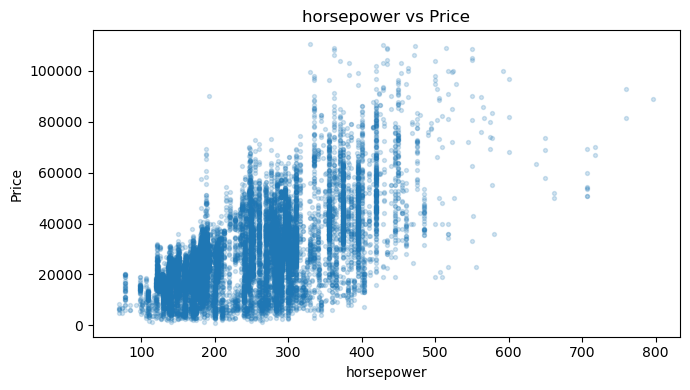

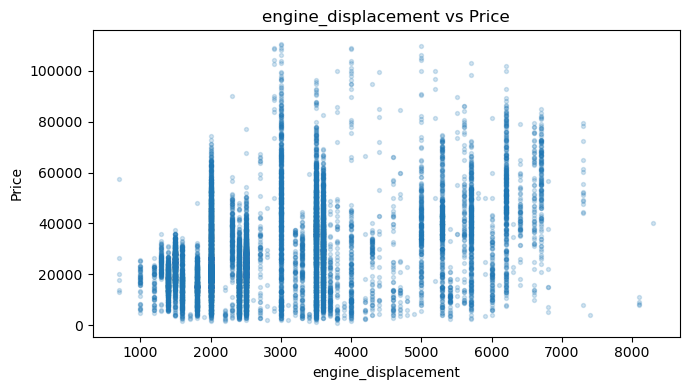

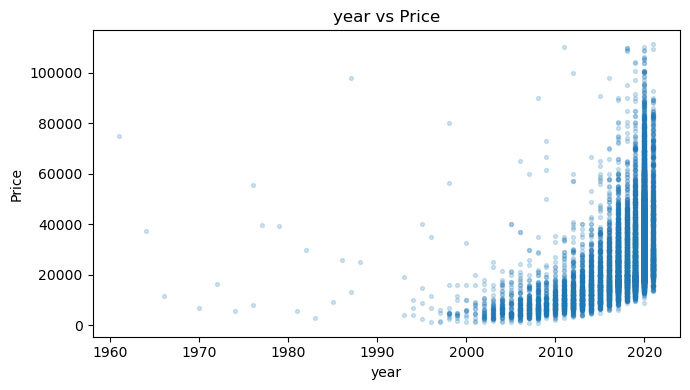

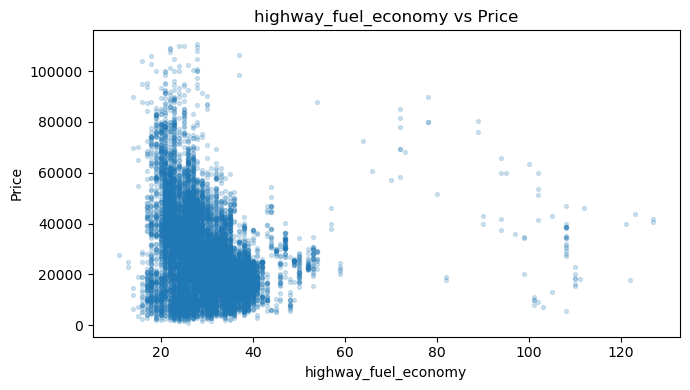

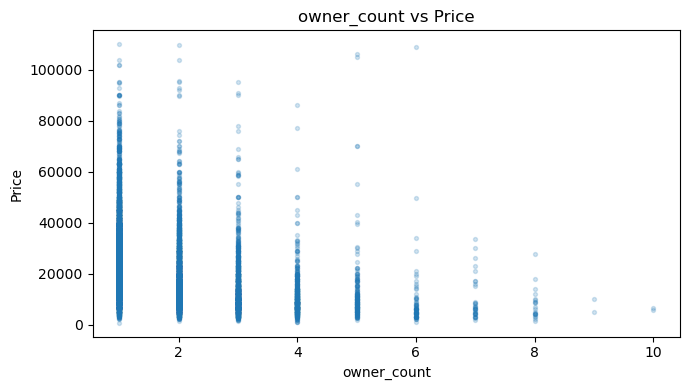

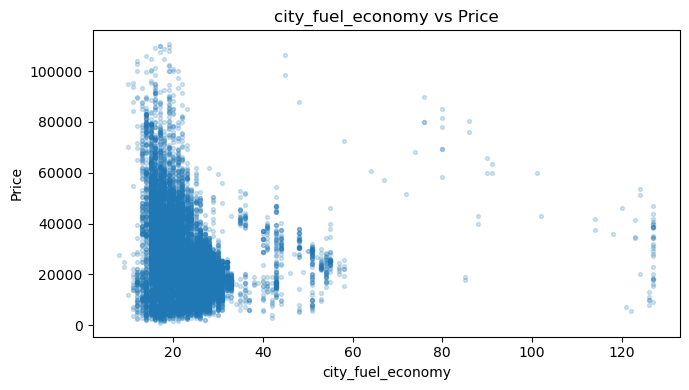

In [17]:
top_features = price_relationships.head(6).index.tolist()

for c in top_features:
    temp = eda_df[[c, "price"]].dropna()

    if len(temp) > 15000:
        temp = temp.sample(15000, random_state=42)

    # Display clipping only.
    price_cap = eda_df["price"].quantile(0.995)
    temp = temp[temp["price"] <= price_cap]

    plt.figure(figsize=(7, 4))
    plt.scatter(temp[c], temp["price"], alpha=0.2, s=8)
    plt.xlabel(c)
    plt.ylabel("Price")
    plt.title(f"{c} vs Price")
    plt.tight_layout()
    plt.show()

### Practical interpretation
The scatterplots confirm that important price relationships are broad rather than perfectly linear. Vehicles with similar horsepower or engine displacement can still have very different prices because make, model, trim, age, mileage, condition, drivetrain, and new/used status also matter.

The nonlinearity visible in mileage-related behavior is consistent with its much stronger Spearman than Pearson correlation.

## 3.3 Categorical features versus price


Price by city


,count,median,mean
city,,,
Scottsdale,6487,"28,345.000","33,512.467"
San Jose,6726,"27,845.000","31,091.557"
Charlotte,8379,"27,635.000","34,410.973"
Houston,32723,"27,395.000","32,095.002"
Richmond,6944,"26,998.000","29,663.810"
Jacksonville,12653,"26,354.000","30,100.486"
Columbia,9568,"26,236.000","30,048.176"
Madison,7031,"26,154.000","29,234.392"
Austin,10653,"25,995.000","30,155.411"


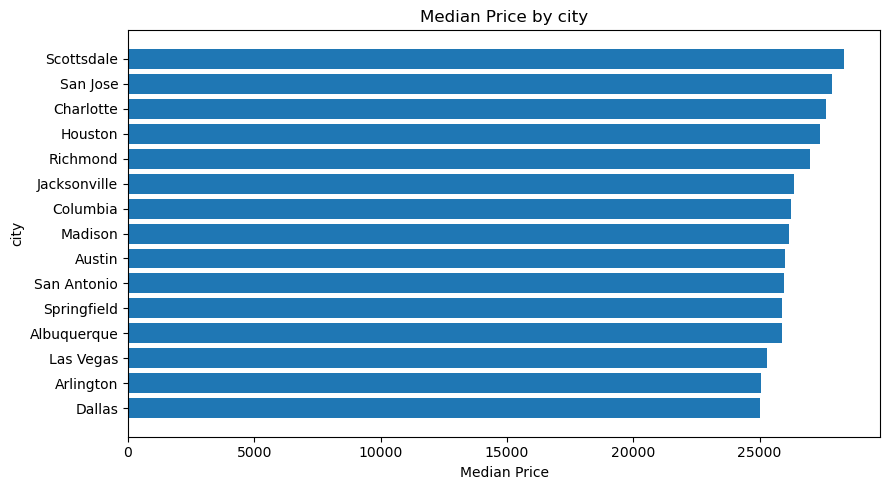


Price by bed


,count,median,mean
bed,,,
Regular,326,"22,248.500","26,792.009"
Long,625,"18,500.000","22,223.891"
Short,1366,"17,995.000","22,066.299"


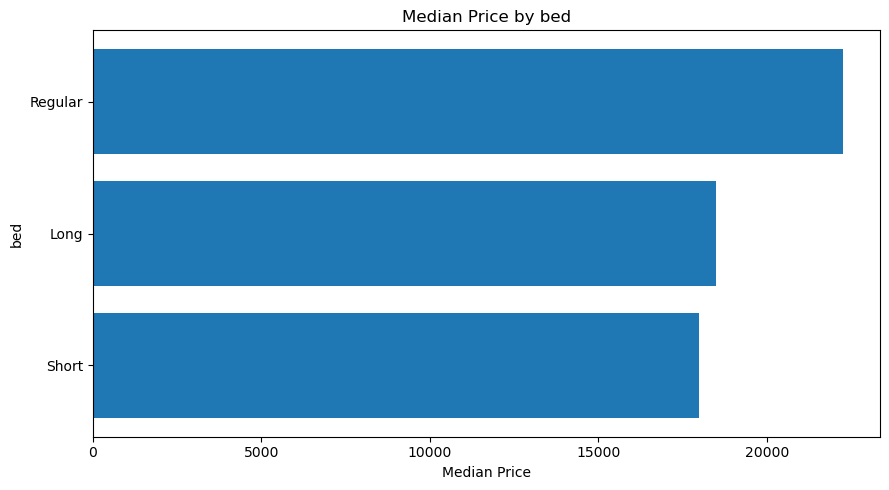


Price by body_type


,count,median,mean
body_type,,,
Pickup Truck,41569,"39,060.000","39,644.305"
Coupe,8870,"27,949.250","40,175.011"
Convertible,3194,"26,995.000","45,267.101"
SUV / Crossover,139227,"26,925.000","30,682.286"
Van,4385,"25,493.000","27,180.398"
Minivan,7954,"23,999.000","24,738.303"
Sedan,82180,"19,172.000","21,703.485"
Hatchback,9645,"15,741.000","16,381.591"
Wagon,4192,"15,498.000","19,297.245"


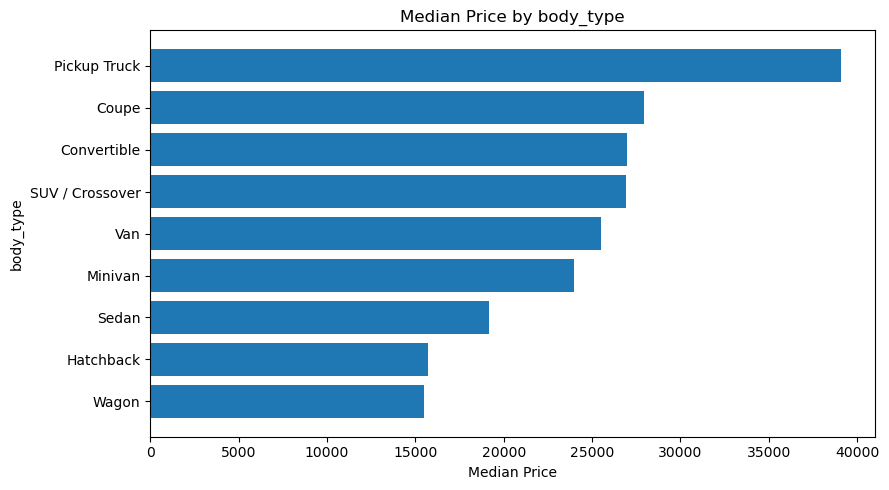


Price by cabin


,count,median,mean
cabin,,,
Large Crew Cab,178,"32,247.500","36,659.854"
Crew Cab,4414,"31,465.000","32,221.843"
Regular Cab,209,"13,900.000","16,817.794"
Extended Cab,754,"12,999.000","15,597.983"


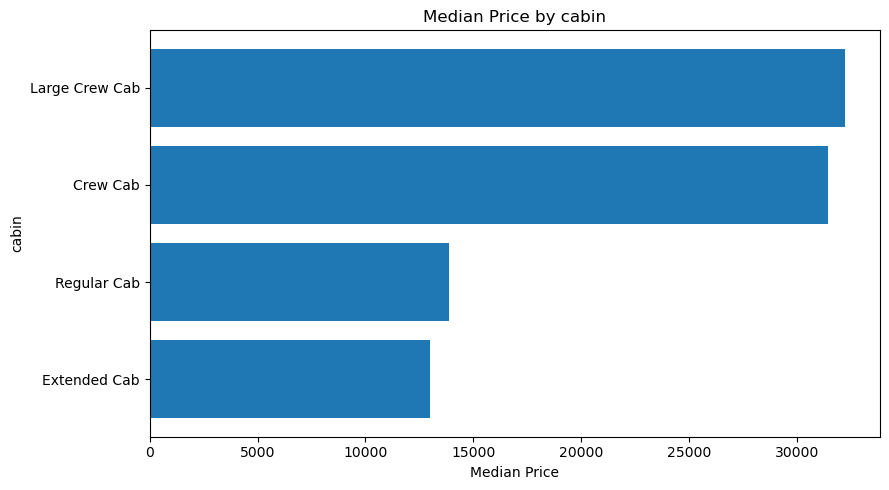


Price by engine_cylinders


,count,median,mean
engine_cylinders,,,
V12,167,"186,883.000","215,538.569"
W12,70,"112,399.000","115,900.071"
V10,161,"103,944.000","113,365.801"
V8 Biodiesel,1757,"59,850.000","58,304.025"
I6 Diesel,2026,"56,062.500","54,371.242"
H6,554,"53,353.500","79,491.987"
V6 Biodiesel,254,"51,716.000","49,066.807"
V6 Diesel,599,"47,923.000","43,557.107"
V8,27582,"42,000.000","45,490.995"


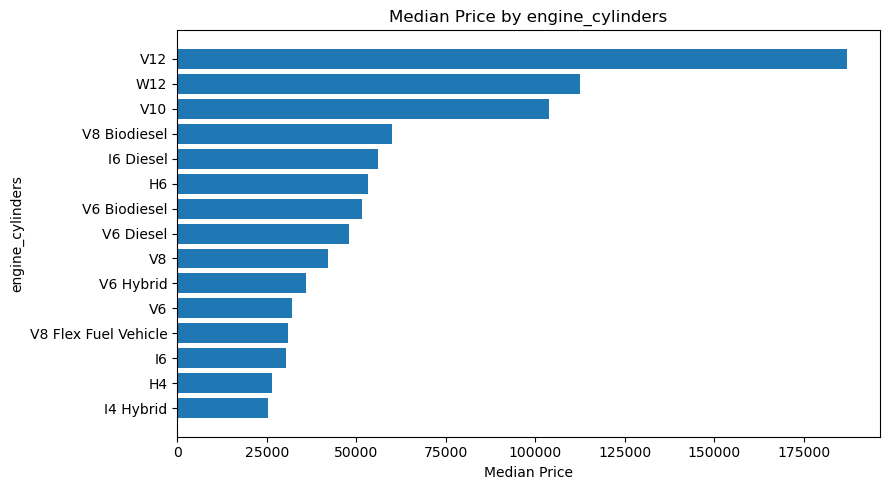


Price by engine_type


,count,median,mean
engine_type,,,
V12,167,"186,883.000","215,538.569"
W12,70,"112,399.000","115,900.071"
V10,161,"103,944.000","113,365.801"
V8 Biodiesel,1757,"59,850.000","58,304.025"
I6 Diesel,2026,"56,062.500","54,371.242"
H6,554,"53,353.500","79,491.987"
V6 Biodiesel,254,"51,716.000","49,066.807"
V6 Diesel,599,"47,923.000","43,557.107"
V8,27582,"42,000.000","45,490.995"


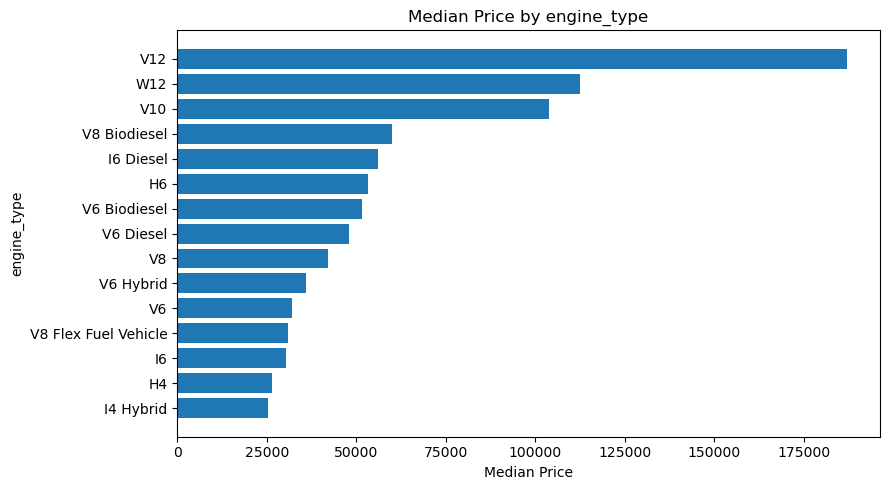


Price by fleet


,count,median,mean
fleet,,,
False,120034,"19,200.000","23,506.404"
True,43052,"17,896.000","19,948.964"


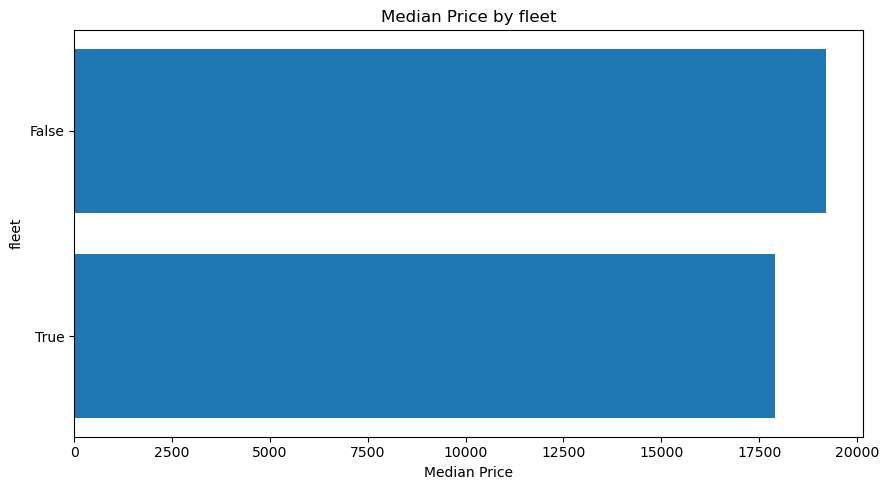


Price by frame_damaged


,count,median,mean
frame_damaged,,,
False,160865,"18,990.000","22,704.970"
True,2221,"10,995.000","12,595.951"


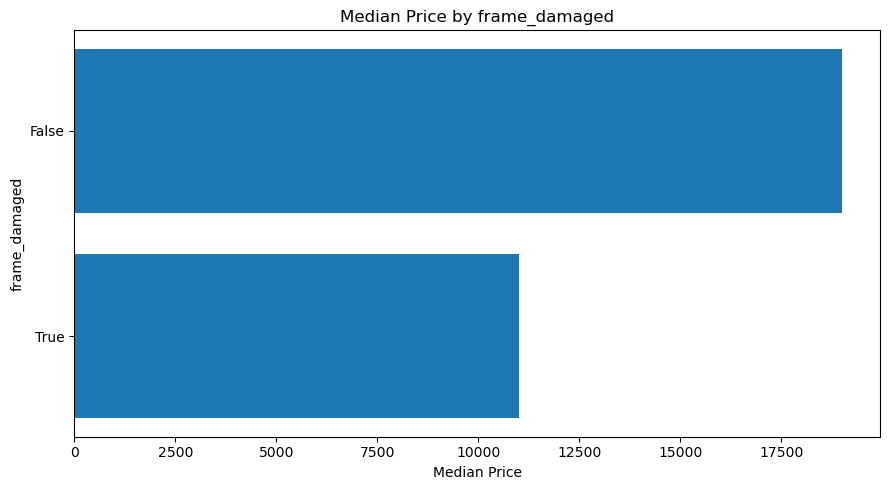


Price by franchise_dealer


,count,median,mean
franchise_dealer,,,
True,224856,"28,315.000","32,818.585"
False,77734,"15,395.000","18,439.104"


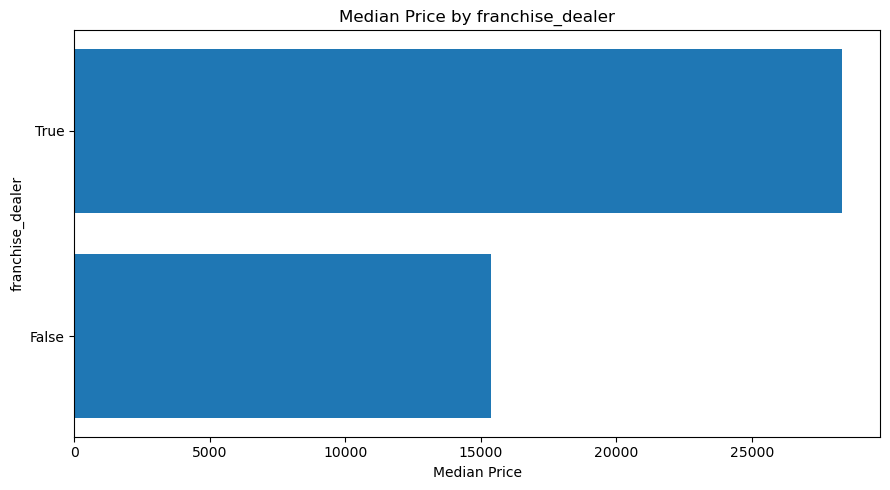


Price by franchise_make


,count,median,mean
franchise_make,,,
Ferrari,54,"239,434.000","285,308.241"
McLaren,120,"209,496.000","210,988.825"
Bentley,62,"123,495.000","139,892.823"
Rolls-Royce,78,"77,370.000","113,768.436"
Porsche,1749,"70,965.000","79,601.333"
Maserati,360,"70,242.000","72,521.981"
Jaguar,714,"52,922.500","55,503.419"
Land Rover,1580,"50,475.000","53,519.128"
RAM,6392,"48,009.000","47,510.686"


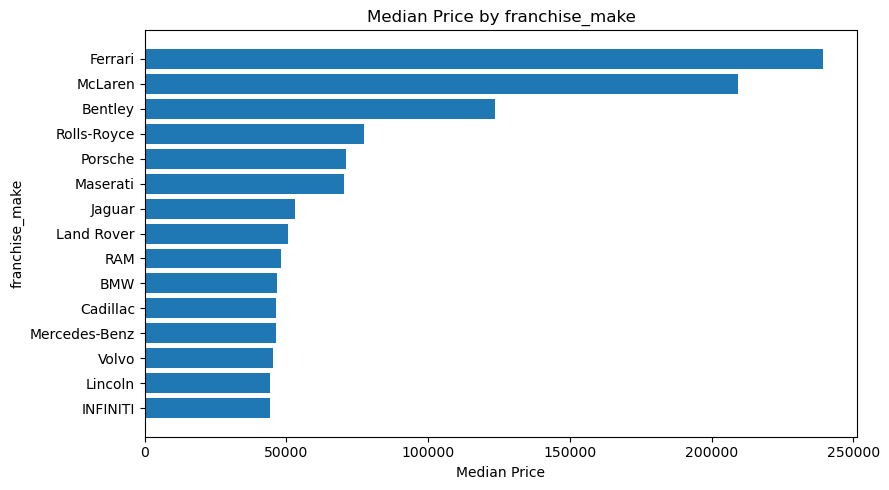


Price by fuel_type


,count,median,mean
fuel_type,,,
Biodiesel,2016,"58,363.500","57,066.511"
Diesel,4065,"45,509.000","40,584.391"
Electric,1812,"32,156.500","40,558.996"
Hybrid,7332,"25,326.500","25,826.534"
Gasoline,264402,"24,851.000","28,611.207"
Flex Fuel Vehicle,14372,"23,998.000","25,826.582"


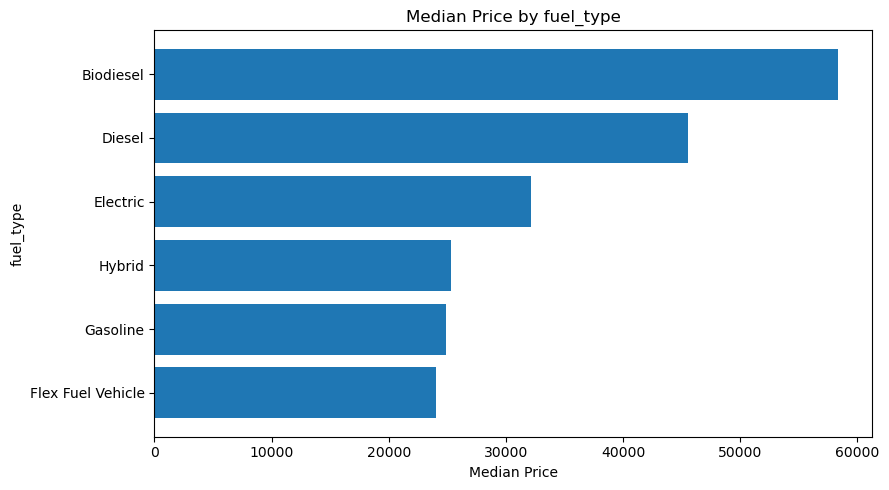


Price by has_accidents


,count,median,mean
has_accidents,,,
False,135636,"19,987.000","23,929.380"
True,27450,"13,397.000","15,836.984"


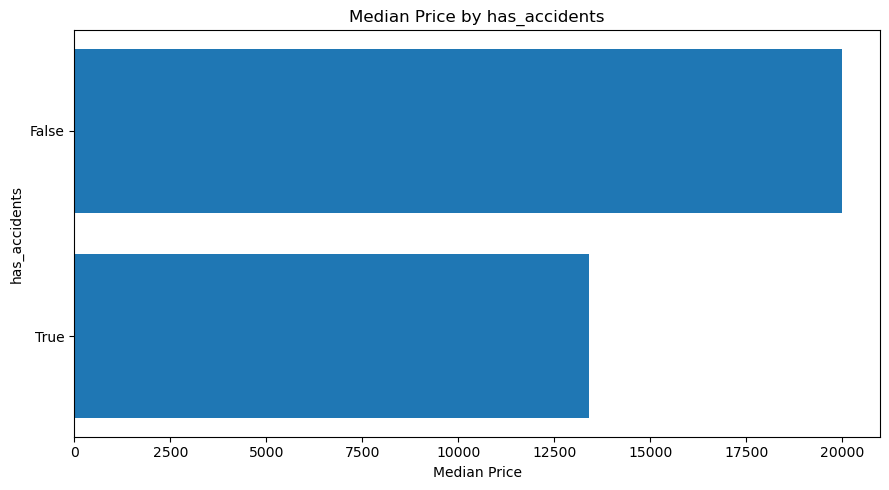


Price by isCab


,count,median,mean
isCab,,,
False,126910,"18,950.000","22,992.575"
True,36176,"18,800.000","21,075.379"


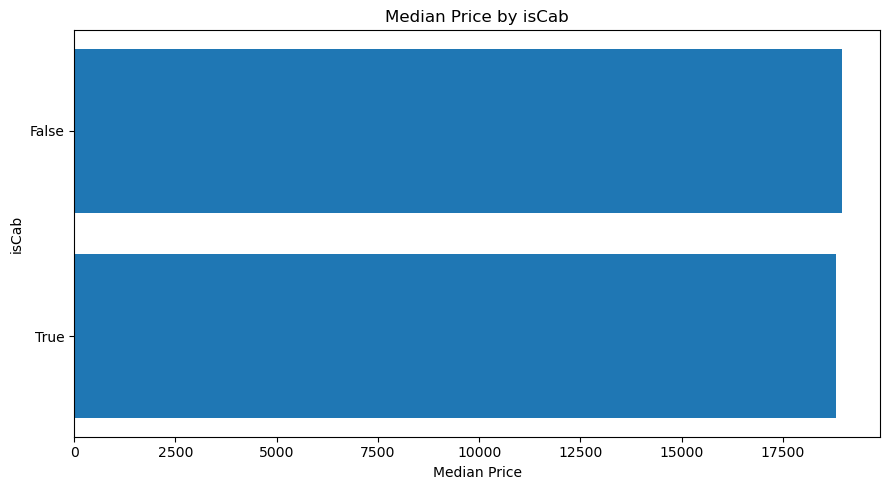


Price by is_new


,count,median,mean
is_new,,,
True,143373,"32,406.000","36,869.374"
False,159217,"18,500.000","22,150.450"


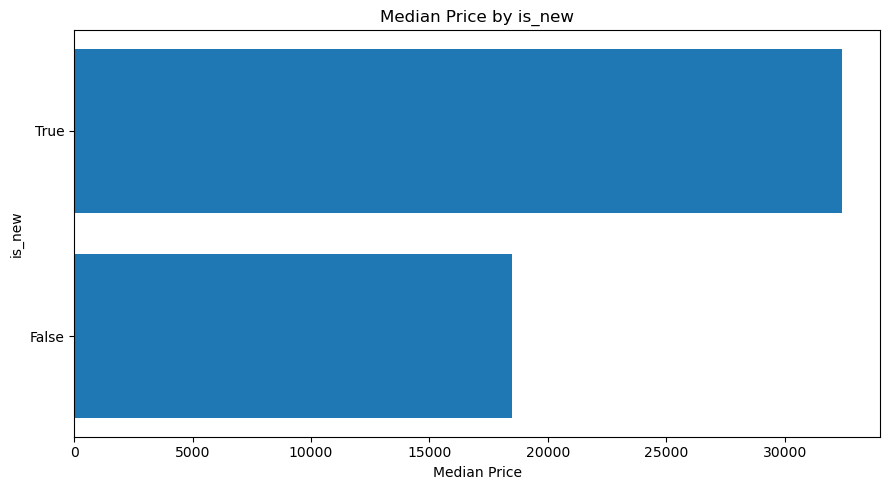


Price by listing_color


,count,median,mean
listing_color,,,
UNKNOWN,38740,"28,000.000","32,377.313"
YELLOW,564,"27,384.000","35,782.676"
WHITE,67272,"26,468.000","30,537.971"
BLACK,59639,"25,965.000","30,483.872"
RED,24504,"24,674.000","28,058.481"
GRAY,39813,"24,450.000","27,810.510"
BLUE,24572,"23,990.000","27,420.531"
GREEN,2230,"23,988.500","28,451.684"
TEAL,516,"23,677.000","22,741.302"


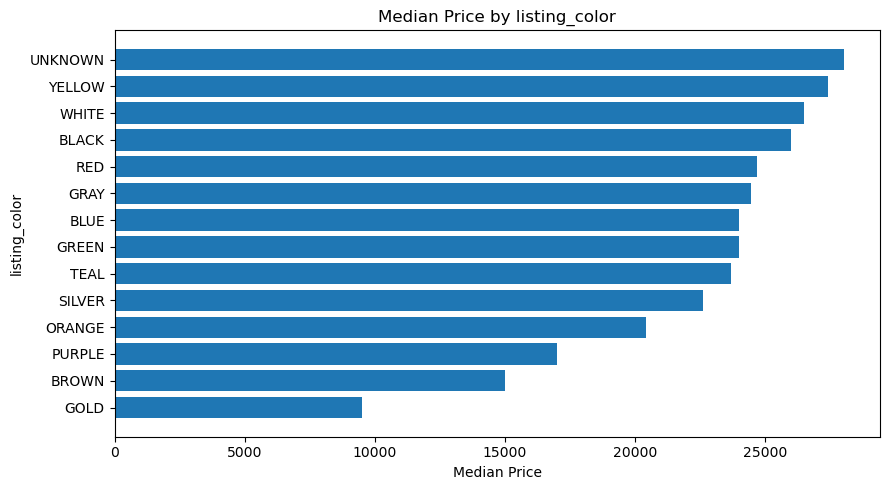


Price by maximum_seating


,count,median,mean
maximum_seating,,,
6 seats,25464,"39,272.500","38,540.559"
8 seats,20094,"37,781.000","39,093.638"
3 seats,2388,"28,995.000","29,194.456"
7 seats,32403,"28,819.000","31,807.186"
2 seats,3916,"25,614.000","50,051.587"
4 seats,9745,"24,700.000","31,286.001"
15 seats,696,"23,087.000","26,946.602"
12 seats,166,"22,995.000","27,313.880"
5 seats,191386,"22,494.000","25,346.979"


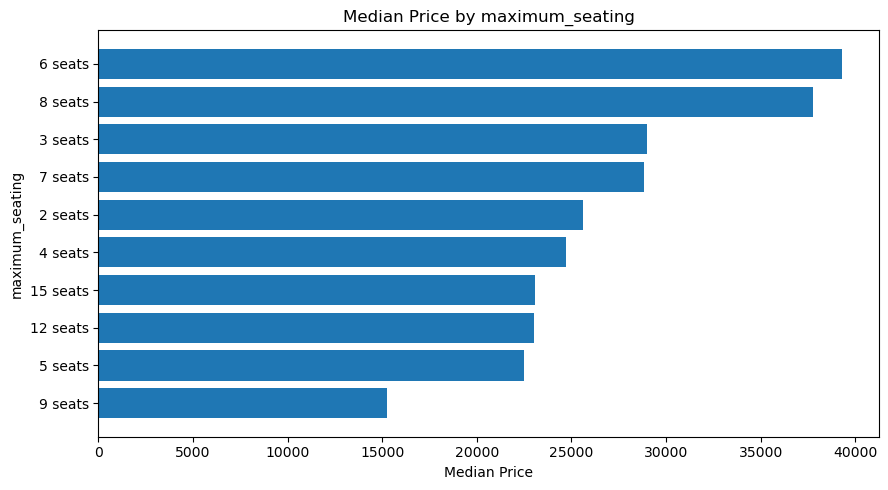


Price by salvage


,count,median,mean
salvage,,,
False,161182,"18,988.000","22,698.317"
True,1904,"8,950.000","11,476.063"


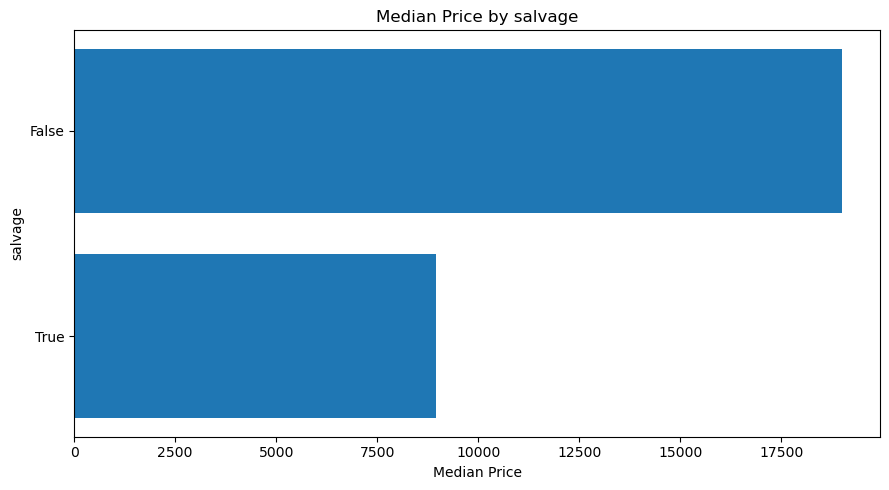


Price by theft_title


,count,median,mean
theft_title,,,
False,162300,"18,944.000","22,596.257"
True,786,"13,496.500","16,587.885"


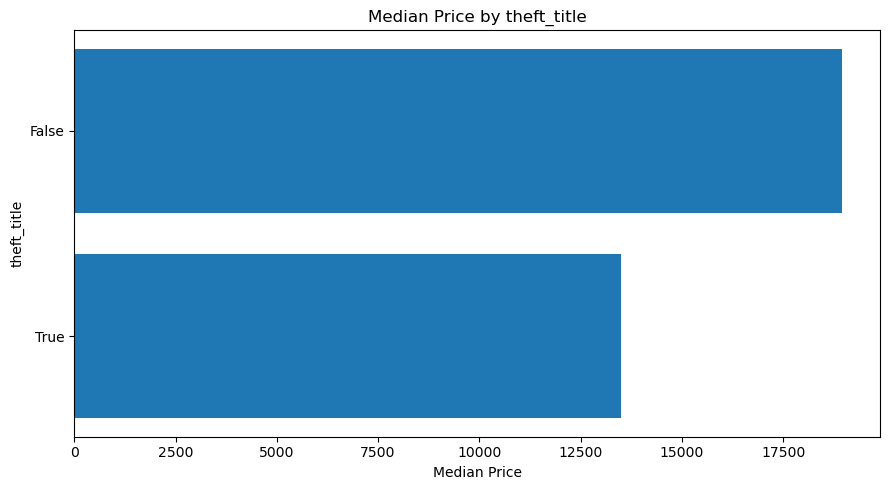


Price by transmission


,count,median,mean
transmission,,,
A,241622,"26,472.500","30,294.608"
Dual Clutch,1211,"24,926.000","28,450.352"
CVT,46534,"21,691.000","22,699.358"
M,5638,"18,197.000","24,904.683"


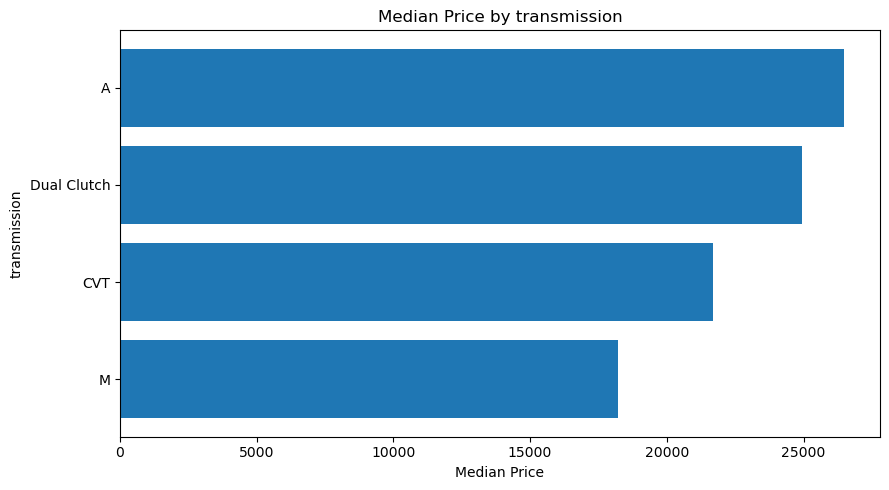


Price by transmission_display


,count,median,mean
transmission_display,,,
7-Speed Manual,62,"57,148.000","67,277.871"
7-Speed Automatic Overdrive,215,"34,981.000","32,322.916"
8-Speed Automatic,31568,"34,925.500","38,182.828"
9-Speed Automatic,11551,"33,000.000","35,860.414"
7-Speed Automatic,5263,"31,050.000","41,261.623"
9-Speed Automatic Overdrive,326,"29,992.500","30,603.632"
7-Speed Dual Clutch,166,"28,975.000","53,235.229"
8-Speed Dual Clutch,397,"28,930.000","30,573.224"
1-Speed Automatic,862,"28,269.000","30,318.577"


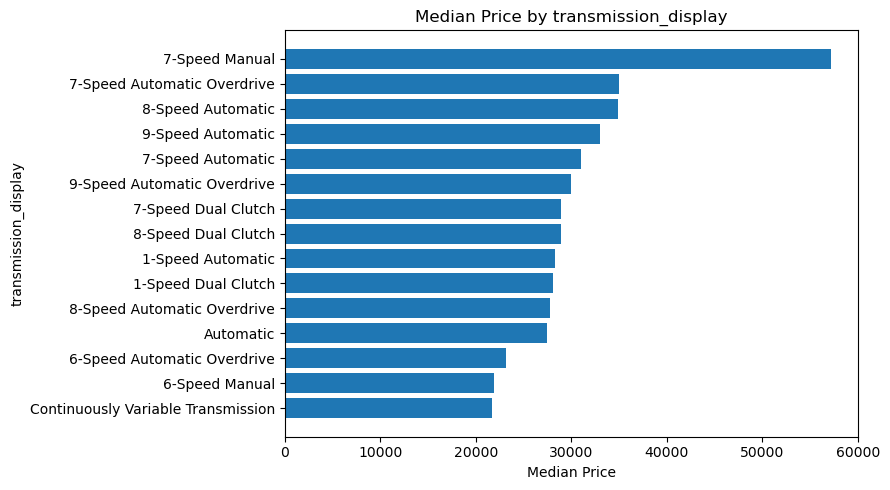


Price by wheel_system


,count,median,mean
wheel_system,,,
4WD,42579,"40,411.000","40,921.876"
4X2,16917,"34,694.000","35,484.355"
AWD,52667,"29,968.000","35,217.688"
RWD,26334,"28,334.000","34,294.777"
FWD,149449,"20,287.000","21,330.441"


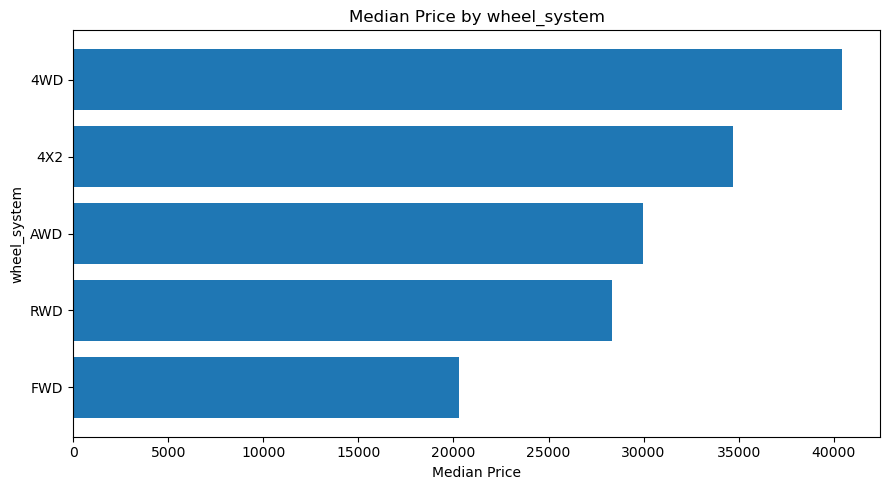


Price by wheel_system_display


,count,median,mean
wheel_system_display,,,
Four-Wheel Drive,42579,"40,411.000","40,921.876"
4X2,16917,"34,694.000","35,484.355"
All-Wheel Drive,52667,"29,968.000","35,217.688"
Rear-Wheel Drive,26334,"28,334.000","34,294.777"
Front-Wheel Drive,149449,"20,287.000","21,330.441"


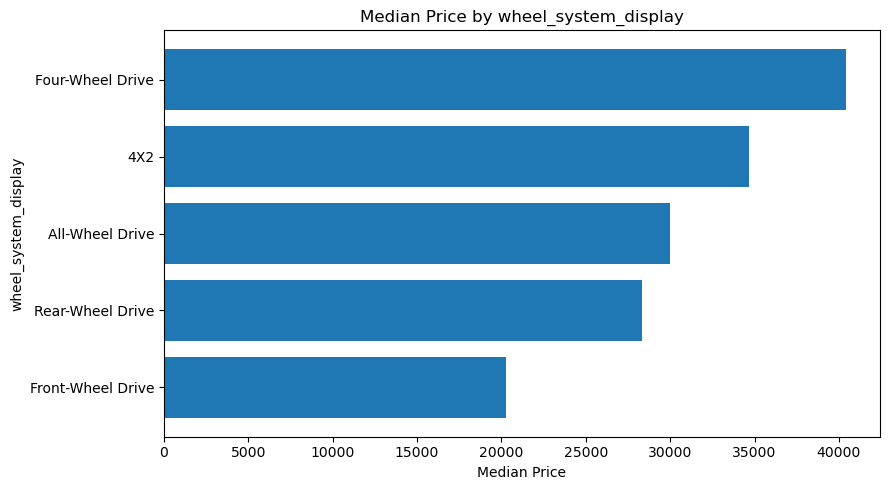

In [18]:
candidate_cats = [
    c for c in cat_cols
    if 2 <= eda_df[c].nunique(dropna=True) <= 50
]

categorical_price_summaries = {}

for c in candidate_cats:
    summary = (
        eda_df[[c, "price"]]
        .dropna()
        .groupby(c)["price"]
        .agg(["count", "median", "mean"])
        .query("count >= 50")
        .sort_values("median", ascending=False)
        .head(15)
    )

    if len(summary) < 2:
        continue

    categorical_price_summaries[c] = summary

    print(f"\nPrice by {c}")
    display(summary)

    plot_data = summary.sort_values("median")

    plt.figure(figsize=(9, 5))
    plt.barh(
        plot_data.index.astype(str),
        plot_data["median"]
    )
    plt.xlabel("Median Price")
    plt.ylabel(c)
    plt.title(f"Median Price by {c}")
    plt.tight_layout()
    plt.show()

### Practical interpretation
Categorical vehicle characteristics also show meaningful price separation.

One clear example from the completed dataset is drivetrain:

- `4WD` median price ≈ **$40,411**
- `4X2` ≈ **$34,694**
- `AWD` ≈ **$29,968**
- `RWD` ≈ **$28,334**
- `FWD` ≈ **$20,287**

This indicates that categorical variables can add substantial predictive information even though ordinary Pearson correlation is not appropriate for nominal categories.

Median price is emphasized because the price distribution is strongly right-skewed and category means can be distorted by a small number of extremely expensive listings.

## 3.4 Are price-related predictors correlated with each other?

,horsepower,engine_displacement,year,highway_fuel_economy,owner_count,city_fuel_economy
horsepower,1.000,0.825,0.018,-0.712,0.009,-0.685
engine_displacement,0.825,1.000,-0.144,-0.708,0.116,-0.682
year,0.018,-0.144,1.000,0.157,-0.596,0.162
highway_fuel_economy,-0.712,-0.708,0.157,1.000,-0.128,0.942
owner_count,0.009,0.116,-0.596,-0.128,1.000,-0.129
city_fuel_economy,-0.685,-0.682,0.162,0.942,-0.129,1.000


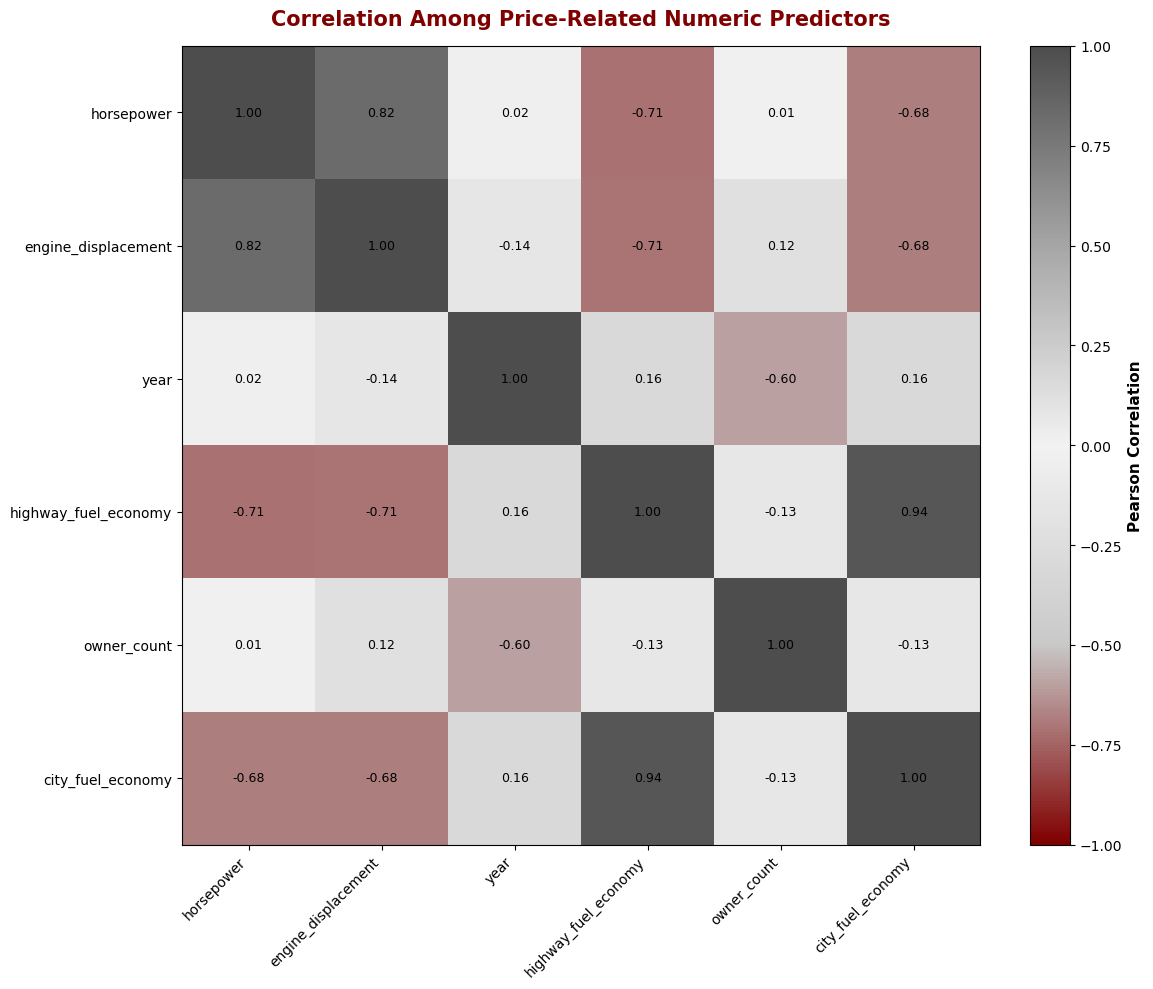

In [24]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

# Select price-related predictors
price_related = price_relationships[
    price_relationships["abs_pearson"] >= 0.15
].index.tolist()

# Calculate predictor correlations
predictor_corr = num_corr[price_related].corr()

display(predictor_corr)

# Custom Maroon–Gray color palette
maroon_gray = LinearSegmentedColormap.from_list(
    "maroon_gray",
    [
        "#800000",   # Maroon = strong negative correlation
        "#C9C9C9",   # Medium gray
        "#F2F2F2",   # Light gray = near zero
        "#A6A6A6",   # Gray
        "#4D4D4D"    # Dark gray = strong positive correlation
    ]
)

# Create heatmap
plt.figure(figsize=(12, 10))

im = plt.imshow(
    predictor_corr.values,
    cmap=maroon_gray,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# Colorbar
cbar = plt.colorbar(im)
cbar.set_label(
    "Pearson Correlation",
    fontsize=11,
    fontweight="bold"
)

# Axis labels
plt.xticks(
    range(len(price_related)),
    price_related,
    rotation=45,
    ha="right",
    fontsize=10
)

plt.yticks(
    range(len(price_related)),
    price_related,
    fontsize=10
)

# Add correlation values inside cells
for i in range(len(price_related)):
    for j in range(len(price_related)):
        value = predictor_corr.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="black"
        )

# Title
plt.title(
    "Correlation Among Price-Related Numeric Predictors",
    fontsize=15,
    fontweight="bold",
    color="#800000",
    pad=15
)

plt.tight_layout()
plt.show()

In [20]:
pairs = []

for i, a in enumerate(price_related):
    for b in price_related[i + 1:]:
        r = predictor_corr.loc[a, b]

        if pd.notna(r):
            pairs.append([
                a,
                b,
                r,
                abs(r)
            ])

pair_table = pd.DataFrame(
    pairs,
    columns=[
        "feature_1",
        "feature_2",
        "correlation",
        "abs_correlation"
    ]
).sort_values("abs_correlation", ascending=False)

display(pair_table.head(20))

print("\nStrong predictor-predictor correlations (|r| >= 0.70):")
display(
    pair_table[
        pair_table["abs_correlation"] >= 0.70
    ]
)

,feature_1,feature_2,correlation,abs_correlation
13,highway_fuel_economy,city_fuel_economy,0.942,0.942
0,horsepower,engine_displacement,0.825,0.825
2,horsepower,highway_fuel_economy,-0.712,0.712
6,engine_displacement,highway_fuel_economy,-0.708,0.708
4,horsepower,city_fuel_economy,-0.685,0.685
8,engine_displacement,city_fuel_economy,-0.682,0.682
10,year,owner_count,-0.596,0.596
11,year,city_fuel_economy,0.162,0.162
9,year,highway_fuel_economy,0.157,0.157
5,engine_displacement,year,-0.144,0.144



Strong predictor-predictor correlations (|r| >= 0.70):


,feature_1,feature_2,correlation,abs_correlation
13,highway_fuel_economy,city_fuel_economy,0.942,0.942
0,horsepower,engine_displacement,0.825,0.825
2,horsepower,highway_fuel_economy,-0.712,0.712
6,engine_displacement,highway_fuel_economy,-0.708,0.708


### Practical interpretation
Yes. Several price-related predictors are strongly correlated with one another.

The completed dataset showed:

- city MPG ↔ highway MPG: **r ≈ 0.942**
- horsepower ↔ engine displacement: **r ≈ 0.825**
- horsepower ↔ highway MPG: **r ≈ −0.712**
- engine displacement ↔ highway MPG: **r ≈ −0.708**

City and highway fuel economy therefore contain substantial overlapping information, as do horsepower and engine displacement.

This creates a multicollinearity concern for an interpretable linear regression. During modeling, VIF, regularization, or selection of representative variables from strongly correlated groups should be considered.

# 4. Final EDA Summary and Preprocessing Handoff

In [21]:
print("=" * 72)
print("FINAL DATASET SUMMARY")
print("=" * 72)

print(
    f"Shape: {df.shape[0]:,} rows × "
    f"{df.shape[1]} columns"
)
print(
    f"Rows with known price: "
    f"{eda_df.shape[0]:,}"
)
print(
    f"Columns with missing values: "
    f"{(df.isna().sum() > 0).sum()}"
)
print(
    f"Completely empty columns: "
    f"{df.isna().all().sum()}"
)
print(
    f"Exact duplicate rows: "
    f"{df.duplicated().sum():,}"
)
print(
    f"High-cardinality categorical/object features: "
    f"{len(high_cardinality)}"
)
print(
    f"Numeric variables screened for outliers: "
    f"{len(outlier_table)}"
)

print("\nTOP NUMERIC RELATIONSHIPS WITH PRICE")
display(price_relationships.head(10))

print("\nSTRONGEST PREDICTOR-TO-PREDICTOR RELATIONSHIPS")
display(pair_table.head(10))

print("\nPREPROCESSING FLAGS")
display(preprocessing_flags)

FINAL DATASET SUMMARY
Shape: 302,590 rows × 66 columns
Rows with known price: 302,590
Columns with missing values: 49
Completely empty columns: 3
Exact duplicate rows: 0
High-cardinality categorical/object features: 21
Numeric variables screened for outliers: 13

TOP NUMERIC RELATIONSHIPS WITH PRICE


,pearson_r,spearman_rho,abs_pearson
horsepower,0.605,0.602,0.605
engine_displacement,0.362,0.366,0.362
year,0.358,0.607,0.358
highway_fuel_economy,-0.243,-0.388,0.243
owner_count,-0.213,-0.450,0.213
city_fuel_economy,-0.169,-0.341,0.169
mileage,-0.106,-0.622,0.106
seller_rating,0.089,0.057,0.089
daysonmarket,0.051,0.028,0.051
savings_amount,0.041,-0.363,0.041



STRONGEST PREDICTOR-TO-PREDICTOR RELATIONSHIPS


,feature_1,feature_2,correlation,abs_correlation
13,highway_fuel_economy,city_fuel_economy,0.942,0.942
0,horsepower,engine_displacement,0.825,0.825
2,horsepower,highway_fuel_economy,-0.712,0.712
6,engine_displacement,highway_fuel_economy,-0.708,0.708
4,horsepower,city_fuel_economy,-0.685,0.685
8,engine_displacement,city_fuel_economy,-0.682,0.682
10,year,owner_count,-0.596,0.596
11,year,city_fuel_economy,0.162,0.162
9,year,highway_fuel_economy,0.157,0.157
5,engine_displacement,year,-0.144,0.144



PREPROCESSING FLAGS


,column,issue,recommended_action
0,Unnamed: 0,Exported row/index field; should not predict v...,Review/drop or transform before modeling.
1,bed_height,Constant/no variation.,Review/drop or transform before modeling.
2,combine_fuel_economy,100% missing; contains no usable information. ...,Review/drop or transform before modeling.
3,is_certified,100% missing; contains no usable information. ...,Review/drop or transform before modeling.
4,is_cpo,Constant/no variation.,Review/drop or transform before modeling.
5,is_oemcpo,Constant/no variation.,Review/drop or transform before modeling.
6,listing_id,Listing identifier; essentially unique and lik...,Review/drop or transform before modeling.
7,main_picture_url,Raw URL/locator with extremely high cardinality.,Review/drop or transform before modeling.
8,sp_id,Seller/dealer identifier. Numeric storage does...,Review/drop or transform before modeling.
9,vehicle_damage_category,100% missing; contains no usable information. ...,Review/drop or transform before modeling.


## Final answers to the assignment questions

### 1. Structure
The dataset contains **302,590 rows and 66 columns** in the completed analysis. It includes numeric, categorical, identifier, free-text, date-like, and unit-bearing string fields.

There are **49 columns with missing values** and **3 completely empty columns**. Important preprocessing flags include empty/constant fields, identifier columns, string measurements, a text date, sparse fields, whitespace/case inconsistencies, high-cardinality free text, and the implausible **99,999,988-mile** observation.

Likely useless or inappropriate raw predictors include `Unnamed: 0`, `listing_id`, `sp_id`, `main_picture_url`, empty columns, and constant fields.

### 2. Univariate distributions
Numeric variables are described with extended statistics and histograms. The largest IQR-based outlier rates occur in `daysonmarket`, `year`, `mileage`, `savings_amount`, `owner_count`, `engine_displacement`, and `price`.

Categorical/object variables are summarized using cardinality tables, value counts, and frequency plots. The dataset contains **21 high-cardinality object/categorical fields** using a >50-level threshold, although several of these are actually measurements or dates stored with the wrong datatype.

### 3. Bivariate relationships
Among variables already stored numerically, `horsepower` has the strongest positive linear correlation with price (**r ≈ 0.605**). Engine displacement and year also have moderate positive relationships.

Mileage is especially important: its Pearson relationship is weak (**r ≈ −0.106**) but its Spearman relationship is strong and negative (**ρ ≈ −0.622**), indicating a nonlinear monotonic decline in price as mileage increases.

Price-related predictors are also correlated with one another. The strongest completed relationships include city MPG with highway MPG (**r ≈ 0.942**) and horsepower with engine displacement (**r ≈ 0.825**), creating a multicollinearity concern.

### Important limitation
The EDA correlation section cannot yet properly test `power`, `torque`, `length`, `width`, `wheelbase`, and similar unit-bearing string fields as numeric predictors. Those should be converted during preprocessing before the final predictive model is built.